In [ ]:
%pip install -q numpy==2.2.6 pandas==2.2.3 scikit-learn xgboost joblib matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.5/16.5 MB 60.4 MB/s eta 0:00:00


In [ ]:
# Upload the dataset CSV, or replace DATA_PATH with a path in /content or Google Drive.
from google.colab import files
uploaded = files.upload()
DATA_PATH = next(iter(uploaded.keys()))
print("Dataset:", DATA_PATH)


Saving InSDN_DatasetCSV.zip to InSDN_DatasetCSV.zip
Dataset: InSDN_DatasetCSV.zip


In [ ]:
# ============================================================
# STEP 0 — EXTRACT + INSPECT InSDN ZIP
# ============================================================

import os
import zipfile
import pandas as pd

print("=" * 80)
print("INSdn DATASET ZIP INSPECTION")
print("=" * 80)

ZIP_PATH = DATA_PATH

# ------------------------------------------------------------
# 1. Verify ZIP
# ------------------------------------------------------------
if not zipfile.is_zipfile(ZIP_PATH):
    raise ValueError(f"Not a valid ZIP file: {ZIP_PATH}")

# ------------------------------------------------------------
# 2. Extract
# ------------------------------------------------------------
EXTRACT_DIR = "/content/insdn_dataset"

os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    members = z.namelist()

    print("\nFiles inside ZIP:")
    for m in members:
        print("  ", m)

    z.extractall(EXTRACT_DIR)

print("\nExtracted to:")
print(EXTRACT_DIR)

# ------------------------------------------------------------
# 3. Find CSV files
# ------------------------------------------------------------
csv_files = []

for root, dirs, files_in_dir in os.walk(EXTRACT_DIR):
    for file in files_in_dir:
        if file.lower().endswith(".csv"):
            csv_files.append(os.path.join(root, file))

print("\nCSV files found:")
for i, path in enumerate(csv_files, 1):
    print(f"{i}. {path}")

# ------------------------------------------------------------
# 4. Inspect every CSV separately
# ------------------------------------------------------------
print("\n" + "=" * 80)
print("INDIVIDUAL CSV INSPECTION")
print("=" * 80)

for path in csv_files:

    print("\n" + "-" * 80)
    print("FILE:", os.path.basename(path))
    print("-" * 80)

    temp = pd.read_csv(path, low_memory=False)

    print("Rows:    ", f"{len(temp):,}")
    print("Columns: ", len(temp.columns))
    print("Shape:   ", temp.shape)

    print("\nColumns:")
    print(temp.columns.tolist())

    if "Label" in temp.columns:
        print("\nLabels:")
        print(temp["Label"].value_counts(dropna=False))

    if "Timestamp" in temp.columns:
        print("\nTimestamp:")
        print("Min:", temp["Timestamp"].min())
        print("Max:", temp["Timestamp"].max())

print("\n" + "=" * 80)
print("ZIP INSPECTION COMPLETE")
print("=" * 80)

INSdn DATASET ZIP INSPECTION

Files inside ZIP:
   InSDN_DatasetCSV/
   InSDN_DatasetCSV/metasploitable-2.csv
   InSDN_DatasetCSV/Normal_data.csv
   InSDN_DatasetCSV/OVS.csv

Extracted to:
/content/insdn_dataset

CSV files found:
1. /content/insdn_dataset/InSDN_DatasetCSV/OVS.csv
2. /content/insdn_dataset/InSDN_DatasetCSV/Normal_data.csv
3. /content/insdn_dataset/InSDN_DatasetCSV/metasploitable-2.csv

INDIVIDUAL CSV INSPECTION

--------------------------------------------------------------------------------
FILE: OVS.csv
--------------------------------------------------------------------------------
Rows:     138,722
Columns:  84
Shape:    (138722, 84)

Columns:
['Flow ID', 'Src IP', 'Src Port', 'Dst IP', 'Dst Port', 'Protocol', 'Timestamp', 'Flow Duration', 'Tot Fwd Pkts', 'Tot Bwd Pkts', 'TotLen Fwd Pkts', 'TotLen Bwd Pkts', 'Fwd Pkt Len Max', 'Fwd Pkt Len Min', 'Fwd Pkt Len Mean', 'Fwd Pkt Len Std', 'Bwd Pkt Len Max', 'Bwd Pkt Len Min', 'Bwd Pkt Len Mean', 'Bwd Pkt Len Std', 'Flow 

In [ ]:
# ============================================================
# STEP 0.1 — FIND THE FROZEN FINAL DDoS EVENT
# ============================================================

import pandas as pd
import os

BASE = "/content/insdn_dataset/InSDN_DatasetCSV"

files_to_check = [
    "OVS.csv",
    "Normal_data.csv",
    "metasploitable-2.csv"
]

TARGET_TS = "2020-10-01 05:57:00"

print("=" * 80)
print("SEARCHING FOR FINAL DDoS EVENT")
print("=" * 80)

for filename in files_to_check:

    path = os.path.join(BASE, filename)

    df_tmp = pd.read_csv(path, low_memory=False)

    # Parse timestamps flexibly
    ts = pd.to_datetime(
        df_tmp["Timestamp"],
        errors="coerce",
        dayfirst=False
    )

    mask = (
        (ts == pd.Timestamp(TARGET_TS)) &
        (df_tmp["Label"].astype(str).str.strip() == "DDoS")
    )

    count = int(mask.sum())

    print(f"\n{filename}")
    print("-" * 60)
    print("Rows:", f"{len(df_tmp):,}")
    print("DDoS rows at target timestamp:", f"{count:,}")

    if count > 0:
        positions = df_tmp.index[mask].to_numpy()

        print("First position:", int(positions[0]))
        print("Last position: ", int(positions[-1]))

        # Check whether contiguous inside this file
        contiguous = (
            positions[-1] - positions[0] + 1 == len(positions)
        )

        print("Contiguous:", contiguous)

        print("\nMatching rows:")
        print(
            df_tmp.loc[
                mask,
                ["Timestamp", "Label"]
            ].head()
        )

print("\n" + "=" * 80)
print("SEARCH COMPLETE")
print("=" * 80)

SEARCHING FOR FINAL DDoS EVENT

OVS.csv
------------------------------------------------------------
Rows: 138,722
DDoS rows at target timestamp: 0

Normal_data.csv
------------------------------------------------------------
Rows: 68,424
DDoS rows at target timestamp: 0

metasploitable-2.csv
------------------------------------------------------------
Rows: 136,743
DDoS rows at target timestamp: 46,309
First position: 300
Last position:  73323
Contiguous: False

Matching rows:
          Timestamp Label
300  10/1/2020 5:57  DDoS
301  10/1/2020 5:57  DDoS
304  10/1/2020 5:57  DDoS
305  10/1/2020 5:57  DDoS
306  10/1/2020 5:57  DDoS

SEARCH COMPLETE


In [ ]:
# ============================================================
# STEP 0.2 — INSPECT THE FINAL DDoS EVENT STRUCTURE
# ============================================================

import pandas as pd
import os

path = "/content/insdn_dataset/InSDN_DatasetCSV/metasploitable-2.csv"

df_meta = pd.read_csv(path, low_memory=False)

# Parse timestamp
df_meta["_ts"] = pd.to_datetime(
    df_meta["Timestamp"],
    errors="coerce",
    dayfirst=False
)

target_ts = pd.Timestamp("2020-10-01 05:57:00")

# Rows at the target timestamp
event = df_meta[
    (df_meta["_ts"] == target_ts) &
    (df_meta["Label"].astype(str).str.strip() == "DDoS")
].copy()

print("=" * 80)
print("FINAL DDoS EVENT STRUCTURE")
print("=" * 80)

print("Total metasploitable rows:", f"{len(df_meta):,}")
print("DDoS rows at target timestamp:", f"{len(event):,}")

print("\nLabel distribution in metasploitable-2:")
print(df_meta["Label"].value_counts())

print("\nRows around first DDoS occurrence:")
print(
    df_meta.loc[
        285:320,
        ["Timestamp", "Label"]
    ].to_string()
)

print("\nRows around last DDoS occurrence:")
print(
    df_meta.loc[
        73300:73340,
        ["Timestamp", "Label"]
    ].to_string()
)

print("\nTarget timestamp distribution:")
print(
    df_meta.loc[
        df_meta["_ts"] == target_ts,
        "Label"
    ].value_counts()
)

print("\nAll timestamps around target:")
print(
    df_meta.loc[
        (df_meta["_ts"] >= target_ts - pd.Timedelta(minutes=1)) &
        (df_meta["_ts"] <= target_ts + pd.Timedelta(minutes=1)),
        ["Timestamp", "Label"]
    ].value_counts()
)

print("=" * 80)

FINAL DDoS EVENT STRUCTURE
Total metasploitable rows: 136,743
DDoS rows at target timestamp: 46,309

Label distribution in metasploitable-2:
Label
DDoS     73529
Probe    61757
DoS       1145
BFA        295
U2R         17
Name: count, dtype: int64

Rows around first DDoS occurrence:
          Timestamp Label
285  10/1/2020 1:40   BFA
286  10/1/2020 1:40   BFA
287  10/1/2020 1:40   BFA
288  10/1/2020 1:40   BFA
289  10/1/2020 1:40   BFA
290  10/1/2020 1:40   BFA
291  10/1/2020 1:40   BFA
292  10/1/2020 1:40   BFA
293  10/1/2020 1:40   BFA
294  10/1/2020 1:40   BFA
295  10/1/2020 3:25   BFA
296  10/1/2020 3:25   BFA
297  10/1/2020 3:25   BFA
298  10/1/2020 5:56  DDoS
299  10/1/2020 5:56  DDoS
300  10/1/2020 5:57  DDoS
301  10/1/2020 5:57  DDoS
302  10/1/2020 5:56  DDoS
303  10/1/2020 5:56  DDoS
304  10/1/2020 5:57  DDoS
305  10/1/2020 5:57  DDoS
306  10/1/2020 5:57  DDoS
307  10/1/2020 5:57  DDoS
308  10/1/2020 5:56  DDoS
309  10/1/2020 5:57  DDoS
310  10/1/2020 5:56  DDoS
311  10/1/2020

In [ ]:
# ============================================================
# STEP 0.3 — IDENTIFY POST-EVENT 1,118 ROWS
# ============================================================

import pandas as pd
import os

BASE = "/content/insdn_dataset/InSDN_DatasetCSV"

files_to_check = [
    "OVS.csv",
    "Normal_data.csv",
    "metasploitable-2.csv"
]

print("=" * 80)
print("SEARCHING FOR THE 1,118 POST-EVENT ROWS")
print("=" * 80)

for filename in files_to_check:

    path = os.path.join(BASE, filename)
    df_tmp = pd.read_csv(path, low_memory=False)

    print("\n" + "-" * 80)
    print(filename)
    print("-" * 80)

    print("Total rows:", f"{len(df_tmp):,}")

    if "Label" in df_tmp.columns:

        bfa = (df_tmp["Label"].astype(str).str.strip() == "BFA").sum()
        u2r = (df_tmp["Label"].astype(str).str.strip() == "U2R").sum()

        print("BFA:", f"{bfa:,}")
        print("U2R:", f"{u2r:,}")
        print("BFA + U2R:", f"{bfa + u2r:,}")

        if bfa + u2r > 0:

            print("\nTimestamp range of BFA/U2R:")
            subset = df_tmp[
                df_tmp["Label"].astype(str).str.strip().isin(["BFA", "U2R"])
            ].copy()

            subset["_ts"] = pd.to_datetime(
                subset["Timestamp"],
                errors="coerce",
                dayfirst=False
            )

            print("Min:", subset["_ts"].min())
            print("Max:", subset["_ts"].max())

            print("\nBFA/U2R timestamp distribution:")
            print(
                subset.groupby(
                    ["Timestamp", "Label"]
                ).size().tail(20)
            )

print("\n" + "=" * 80)
print("SEARCH COMPLETE")
print("=" * 80)

SEARCHING FOR THE 1,118 POST-EVENT ROWS

--------------------------------------------------------------------------------
OVS.csv
--------------------------------------------------------------------------------
Total rows: 138,722
BFA: 1,110
U2R: 0
BFA + U2R: 1,110

Timestamp range of BFA/U2R:
Min: 2020-12-01 01:14:00
Max: 2020-12-01 01:27:00

BFA/U2R timestamp distribution:
Timestamp       Label
12/1/2020 1:14  BFA       60
12/1/2020 1:15  BFA       54
12/1/2020 1:16  BFA       34
12/1/2020 1:17  BFA       30
12/1/2020 1:18  BFA       24
12/1/2020 1:19  BFA       22
12/1/2020 1:20  BFA       20
12/1/2020 1:21  BFA       18
12/1/2020 1:22  BFA       18
12/1/2020 1:23  BFA        8
12/1/2020 1:27  BFA      822
dtype: int64

--------------------------------------------------------------------------------
Normal_data.csv
--------------------------------------------------------------------------------
Total rows: 68,424
BFA: 0
U2R: 0
BFA + U2R: 0

------------------------------------------

In [ ]:
# ============================================================
# STEP 0.4 — INSPECT ALL BFA/U2R AFTER FINAL DDoS TIMESTAMP
# ============================================================

import pandas as pd
import os

BASE = "/content/insdn_dataset/InSDN_DatasetCSV"

files_to_check = [
    "OVS.csv",
    "Normal_data.csv",
    "metasploitable-2.csv"
]

frames = []

for filename in files_to_check:

    path = os.path.join(BASE, filename)

    tmp = pd.read_csv(path, low_memory=False)

    tmp["_source_file"] = filename

    tmp["_ts"] = pd.to_datetime(
        tmp["Timestamp"],
        errors="coerce",
        dayfirst=False
    )

    frames.append(tmp)

all_raw = pd.concat(frames, ignore_index=True)

target_ts = pd.Timestamp("2020-10-01 05:57:00")

# BFA/U2R rows
bu = all_raw[
    all_raw["Label"].astype(str).str.strip().isin(["BFA", "U2R"])
].copy()

print("=" * 80)
print("ALL BFA / U2R ROWS")
print("=" * 80)

print("Total BFA/U2R:", f"{len(bu):,}")

print("\nBy source:")
print(bu["_source_file"].value_counts())

print("\nBy label:")
print(bu["Label"].value_counts())

# ------------------------------------------------------------
# Rows AFTER final DDoS timestamp
# ------------------------------------------------------------

after = bu[bu["_ts"] > target_ts].copy()

print("\n" + "=" * 80)
print("BFA/U2R AFTER 2020-10-01 05:57")
print("=" * 80)

print("Rows:", f"{len(after):,}")

print("\nBy source:")
print(after["_source_file"].value_counts())

print("\nBy label:")
print(after["Label"].value_counts())

print("\nTimestamp range:")
print("Min:", after["_ts"].min())
print("Max:", after["_ts"].max())

print("\nTimestamp distribution:")
print(
    after.groupby(["_ts", "Label", "_source_file"])
         .size()
         .sort_index()
         .to_string()
)

# ------------------------------------------------------------
# Rows BEFORE final DDoS timestamp
# ------------------------------------------------------------

before = bu[bu["_ts"] < target_ts].copy()

print("\n" + "=" * 80)
print("BFA/U2R BEFORE 2020-10-01 05:57")
print("=" * 80)

print("Rows:", f"{len(before):,}")

print("\nBy source:")
print(before["_source_file"].value_counts())

print("\nBy label:")
print(before["Label"].value_counts())

print("=" * 80)

ALL BFA / U2R ROWS
Total BFA/U2R: 1,422

By source:
_source_file
OVS.csv                 1110
metasploitable-2.csv     312
Name: count, dtype: int64

By label:
Label
BFA    1405
U2R      17
Name: count, dtype: int64

BFA/U2R AFTER 2020-10-01 05:57
Rows: 1,118

By source:
_source_file
OVS.csv                 1110
metasploitable-2.csv       8
Name: count, dtype: int64

By label:
Label
BFA    1110
U2R       8
Name: count, dtype: int64

Timestamp range:
Min: 2020-10-01 16:52:00
Max: 2020-12-01 01:27:00

Timestamp distribution:
_ts                  Label  _source_file        
2020-10-01 16:52:00  U2R    metasploitable-2.csv      3
2020-10-01 20:36:00  U2R    metasploitable-2.csv      3
2020-10-01 20:57:00  U2R    metasploitable-2.csv      2
2020-12-01 01:14:00  BFA    OVS.csv                  60
2020-12-01 01:15:00  BFA    OVS.csv                  54
2020-12-01 01:16:00  BFA    OVS.csv                  34
2020-12-01 01:17:00  BFA    OVS.csv                  30
2020-12-01 01:18:00  BFA    OV

In [ ]:
# ============================================================
# STEP 0.3 — IDENTIFY POST-EVENT 1,118 ROWS
# ============================================================

import pandas as pd
import os

BASE = "/content/insdn_dataset/InSDN_DatasetCSV"

files_to_check = [
    "OVS.csv",
    "Normal_data.csv",
    "metasploitable-2.csv"
]

print("=" * 80)
print("SEARCHING FOR THE 1,118 POST-EVENT ROWS")
print("=" * 80)

for filename in files_to_check:

    path = os.path.join(BASE, filename)
    df_tmp = pd.read_csv(path, low_memory=False)

    print("\n" + "-" * 80)
    print(filename)
    print("-" * 80)

    print("Total rows:", f"{len(df_tmp):,}")

    if "Label" in df_tmp.columns:

        bfa = (df_tmp["Label"].astype(str).str.strip() == "BFA").sum()
        u2r = (df_tmp["Label"].astype(str).str.strip() == "U2R").sum()

        print("BFA:", f"{bfa:,}")
        print("U2R:", f"{u2r:,}")
        print("BFA + U2R:", f"{bfa + u2r:,}")

        if bfa + u2r > 0:

            print("\nTimestamp range of BFA/U2R:")
            subset = df_tmp[
                df_tmp["Label"].astype(str).str.strip().isin(["BFA", "U2R"])
            ].copy()

            subset["_ts"] = pd.to_datetime(
                subset["Timestamp"],
                errors="coerce",
                dayfirst=False
            )

            print("Min:", subset["_ts"].min())
            print("Max:", subset["_ts"].max())

            print("\nBFA/U2R timestamp distribution:")
            print(
                subset.groupby(
                    ["Timestamp", "Label"]
                ).size().tail(20)
            )

print("\n" + "=" * 80)
print("SEARCH COMPLETE")
print("=" * 80)

SEARCHING FOR THE 1,118 POST-EVENT ROWS

--------------------------------------------------------------------------------
OVS.csv
--------------------------------------------------------------------------------
Total rows: 138,722
BFA: 1,110
U2R: 0
BFA + U2R: 1,110

Timestamp range of BFA/U2R:
Min: 2020-12-01 01:14:00
Max: 2020-12-01 01:27:00

BFA/U2R timestamp distribution:
Timestamp       Label
12/1/2020 1:14  BFA       60
12/1/2020 1:15  BFA       54
12/1/2020 1:16  BFA       34
12/1/2020 1:17  BFA       30
12/1/2020 1:18  BFA       24
12/1/2020 1:19  BFA       22
12/1/2020 1:20  BFA       20
12/1/2020 1:21  BFA       18
12/1/2020 1:22  BFA       18
12/1/2020 1:23  BFA        8
12/1/2020 1:27  BFA      822
dtype: int64

--------------------------------------------------------------------------------
Normal_data.csv
--------------------------------------------------------------------------------
Total rows: 68,424
BFA: 0
U2R: 0
BFA + U2R: 0

------------------------------------------

In [ ]:
# ============================================================
# STEP 0.5 — CONSTRUCT CANDIDATE MASTER DATASET
# ============================================================

import pandas as pd
import numpy as np
import os

BASE = "/content/insdn_dataset/InSDN_DatasetCSV"

print("=" * 80)
print("CONSTRUCTING CANDIDATE MASTER DATASET")
print("=" * 80)

# ------------------------------------------------------------
# 1. Load the three original CSVs
# ------------------------------------------------------------

ovs = pd.read_csv(os.path.join(BASE, "OVS.csv"), low_memory=False)
normal = pd.read_csv(os.path.join(BASE, "Normal_data.csv"), low_memory=False)
meta = pd.read_csv(
    os.path.join(BASE, "metasploitable-2.csv"),
    low_memory=False
)

print("OVS:             ", f"{len(ovs):,}")
print("Normal:          ", f"{len(normal):,}")
print("Metasploitable:  ", f"{len(meta):,}")

# ------------------------------------------------------------
# 2. Add unique source-row IDs
# ------------------------------------------------------------

ovs["_source_file"] = "OVS.csv"
normal["_source_file"] = "Normal_data.csv"
meta["_source_file"] = "metasploitable-2.csv"

ovs["_source_row"] = np.arange(len(ovs))
normal["_source_row"] = np.arange(len(normal))
meta["_source_row"] = np.arange(len(meta))

# ------------------------------------------------------------
# 3. Parse timestamps
# ------------------------------------------------------------

for d in (ovs, normal, meta):
    d["_ts"] = pd.to_datetime(
        d["Timestamp"],
        errors="coerce",
        dayfirst=False
    )

FINAL_TS = pd.Timestamp("2020-10-01 05:57:00")

# ------------------------------------------------------------
# 4. Identify the EXACT final DDoS event
# ------------------------------------------------------------

final_ddos = meta[
    (meta["_ts"] == FINAL_TS) &
    (meta["Label"].astype(str).str.strip() == "DDoS")
].copy()

print("\nFinal DDoS rows:", f"{len(final_ddos):,}")

assert len(final_ddos) == 46_309

# ------------------------------------------------------------
# 5. Identify EXACT post-event rows
# ------------------------------------------------------------

post_meta = meta[
    (meta["_ts"] > FINAL_TS) &
    (meta["Label"].astype(str).str.strip().isin(["BFA", "U2R"]))
].copy()

post_ovs = ovs[
    (ovs["_ts"] > FINAL_TS) &
    (ovs["Label"].astype(str).str.strip().isin(["BFA", "U2R"]))
].copy()

post_event = pd.concat(
    [post_meta, post_ovs],
    ignore_index=True
)

print("Post-event rows:", f"{len(post_event):,}")
print("\nPost-event labels:")
print(post_event["Label"].value_counts())

assert len(post_event) == 1_118
assert set(post_event["Label"].astype(str).str.strip()) <= {"BFA", "U2R"}

# ------------------------------------------------------------
# 6. Create exact row keys
# ------------------------------------------------------------

final_keys = set(
    zip(
        final_ddos["_source_file"],
        final_ddos["_source_row"]
    )
)

post_keys = set(
    zip(
        post_event["_source_file"],
        post_event["_source_row"]
    )
)

# ------------------------------------------------------------
# 7. Combine original files
# ------------------------------------------------------------

all_raw = pd.concat(
    [ovs, normal, meta],
    ignore_index=True
)

all_raw["_row_key"] = list(
    zip(
        all_raw["_source_file"],
        all_raw["_source_row"]
    )
)

# ------------------------------------------------------------
# 8. Remove only the exact final-event + post-event rows
# ------------------------------------------------------------

excluded_keys = final_keys | post_keys

development = all_raw[
    ~all_raw["_row_key"].isin(excluded_keys)
].copy()

print("\nCandidate development rows:",
      f"{len(development):,}")

# ------------------------------------------------------------
# 9. Candidate master
# ------------------------------------------------------------

master = pd.concat(
    [
        development,
        final_ddos,
        post_event
    ],
    ignore_index=True
)

print("\nCandidate master rows:",
      f"{len(master):,}")

# ------------------------------------------------------------
# 10. Verify arithmetic
# ------------------------------------------------------------

assert len(development) == 296_462
assert len(final_ddos) == 46_309
assert len(post_event) == 1_118
assert len(master) == 343_889

print("\n" + "=" * 80)
print("ROW COUNTS VERIFIED")
print("=" * 80)

print("Development :", f"{len(development):,}")
print("Final DDoS   :", f"{len(final_ddos):,}")
print("Post-event   :", f"{len(post_event):,}")
print("-----------------------------")
print("TOTAL        :", f"{len(master):,}")

# ------------------------------------------------------------
# 11. Check candidate final block
# ------------------------------------------------------------

candidate_final = master.iloc[296_462:342_771]

print("\nCandidate final block:")
print(candidate_final["Label"].value_counts())

print("\nCandidate final timestamps:")
print(candidate_final["_ts"].value_counts().head())

# ------------------------------------------------------------
# 12. Check candidate post-event block
# ------------------------------------------------------------

candidate_post = master.iloc[342_771:]

print("\nCandidate post-event block:")
print(candidate_post["Label"].value_counts())

print("\nCandidate post-event sources:")
print(candidate_post["_source_file"].value_counts())

print("=" * 80)
print("CANDIDATE MASTER CONSTRUCTION COMPLETE")
print("=" * 80)

CONSTRUCTING CANDIDATE MASTER DATASET
OVS:              138,722
Normal:           68,424
Metasploitable:   136,743

Final DDoS rows: 46,309
Post-event rows: 1,118

Post-event labels:
Label
BFA    1110
U2R       8
Name: count, dtype: int64

Candidate development rows: 296,462

Candidate master rows: 343,889

ROW COUNTS VERIFIED
Development : 296,462
Final DDoS   : 46,309
Post-event   : 1,118
-----------------------------
TOTAL        : 343,889

Candidate final block:
Label
DDoS    46309
Name: count, dtype: int64

Candidate final timestamps:
_ts
2020-10-01 05:57:00    46309
Name: count, dtype: int64

Candidate post-event block:
Label
BFA    1110
U2R       8
Name: count, dtype: int64

Candidate post-event sources:
_source_file
OVS.csv                 1110
metasploitable-2.csv       8
Name: count, dtype: int64
CANDIDATE MASTER CONSTRUCTION COMPLETE


In [ ]:
# ============================================================
# STEP 0.6 — STRICT CHRONOLOGICAL VALIDATION
# ============================================================

print("=" * 80)
print("STRICT CHRONOLOGICAL VALIDATION")
print("=" * 80)

# ------------------------------------------------------------
# 1. Parse timestamps robustly
# ------------------------------------------------------------
# The three source CSVs contain mixed timestamp formats.
# format="mixed" handles those formats safely.

master["_ts_check"] = pd.to_datetime(
    master["Timestamp"],
    format="mixed",
    errors="coerce",
    dayfirst=False
)

# ------------------------------------------------------------
# 2. Check for invalid timestamps
# ------------------------------------------------------------
invalid_ts = int(master["_ts_check"].isna().sum())

print(f"Invalid timestamps: {invalid_ts}")

assert invalid_ts == 0, (
    f"Found {invalid_ts} invalid timestamps."
)

# ------------------------------------------------------------
# 3. Check global chronological ordering
# ------------------------------------------------------------
is_monotonic = master["_ts_check"].is_monotonic_increasing

print(f"Globally chronological: {is_monotonic}")

assert is_monotonic, (
    "Candidate master is NOT chronologically ordered."
)

# ------------------------------------------------------------
# 4. Exact final DDoS event
# ------------------------------------------------------------
FINAL_START = 296_462
FINAL_END_EXCLUSIVE = 342_771

FINAL_TS = pd.Timestamp("2020-10-01 05:57:00")

final_block = master.iloc[
    FINAL_START:FINAL_END_EXCLUSIVE
]

print("\n" + "-" * 80)
print("FINAL DDoS EVENT")
print("-" * 80)

print(f"Rows      : {len(final_block):,}")
print(f"Timestamp : {final_block['_ts_check'].min()}")
print(f"Timestamp : {final_block['_ts_check'].max()}")

print("\nLabels:")
print(final_block["Label"].value_counts())

# Exact size
assert len(final_block) == 46_309, (
    f"Final block has {len(final_block):,} rows; expected 46,309."
)

# Exact timestamp
assert final_block["_ts_check"].nunique() == 1, (
    "Final DDoS block contains multiple timestamps."
)

assert final_block["_ts_check"].iloc[0] == FINAL_TS, (
    "Final DDoS timestamp is not 2020-10-01 05:57:00."
)

# Every row must be DDoS
assert final_block["Label"].eq("DDoS").all(), (
    "Final block contains labels other than DDoS."
)

# ------------------------------------------------------------
# 5. Check exact event positions
# ------------------------------------------------------------
event_mask = (
    (master["_ts_check"] == FINAL_TS)
    & (master["Label"] == "DDoS")
)

event_positions = np.flatnonzero(event_mask.to_numpy())

print("\n" + "-" * 80)
print("EXACT EVENT POSITION")
print("-" * 80)

print(f"Event rows : {len(event_positions):,}")
print(f"Start      : {event_positions[0]:,}")
print(f"End        : {event_positions[-1]:,}")

assert len(event_positions) == 46_309, (
    "Number of final DDoS rows does not equal 46,309."
)

assert event_positions[0] == 296_462, (
    f"Final event starts at {event_positions[0]:,}; "
    "expected 296,462."
)

assert event_positions[-1] == 342_770, (
    f"Final event ends at {event_positions[-1]:,}; "
    "expected 342,770."
)

# Check contiguity
assert (
    event_positions[-1] - event_positions[0] + 1
    == len(event_positions)
), (
    "Final DDoS rows are NOT contiguous."
)

# ------------------------------------------------------------
# 6. Row immediately before final event
# ------------------------------------------------------------
before_final = master.iloc[FINAL_START - 1]

print("\n" + "-" * 80)
print("ROW IMMEDIATELY BEFORE FINAL EVENT")
print("-" * 80)

print("Timestamp:", before_final["_ts_check"])
print("Label    :", before_final["Label"])

assert before_final["_ts_check"] < FINAL_TS, (
    "Row immediately before final event is not earlier than final timestamp."
)

# ------------------------------------------------------------
# 7. Row immediately after final DDoS event
# ------------------------------------------------------------
after_final = master.iloc[FINAL_END_EXCLUSIVE]

print("\n" + "-" * 80)
print("ROW IMMEDIATELY AFTER FINAL EVENT")
print("-" * 80)

print("Timestamp:", after_final["_ts_check"])
print("Label    :", after_final["Label"])

assert after_final["_ts_check"] > FINAL_TS, (
    "Row immediately after final event is not later than final timestamp."
)

# ------------------------------------------------------------
# 8. Validate post-event block
# ------------------------------------------------------------
POST_START = 342_771

post_block = master.iloc[POST_START:]

print("\n" + "-" * 80)
print("POST-EVENT BLOCK")
print("-" * 80)

print(f"Rows: {len(post_block):,}")

print("\nLabels:")
print(post_block["Label"].value_counts())

# Exact size
assert len(post_block) == 1_118, (
    f"Post-event block has {len(post_block):,} rows; "
    "expected 1,118."
)

# Only BFA and U2R
post_labels = set(post_block["Label"].unique())

assert post_labels <= {"BFA", "U2R"}, (
    f"Unexpected post-event labels: {post_labels}"
)

# Must all occur after final event
assert (post_block["_ts_check"] > FINAL_TS).all(), (
    "Post-event block contains rows at or before the final event timestamp."
)

# ------------------------------------------------------------
# 9. Verify total rows
# ------------------------------------------------------------
print("\n" + "-" * 80)
print("ROW CONSERVATION")
print("-" * 80)

print(f"Development : {FINAL_START:,}")
print(f"Final DDoS  : {len(final_block):,}")
print(f"Post-event  : {len(post_block):,}")
print("-" * 80)
print(f"TOTAL       : {len(master):,}")

assert len(master) == 343_889, (
    f"Master has {len(master):,} rows; expected 343,889."
)

assert (
    FINAL_START
    + len(final_block)
    + len(post_block)
    == len(master)
), "Row conservation failed."

# ------------------------------------------------------------
# 10. Boundary inspection
# ------------------------------------------------------------
print("\n" + "=" * 80)
print("BOUNDARY INSPECTION")
print("=" * 80)

print("\nLast 5 DEVELOPMENT rows:")
display(
    master.iloc[FINAL_START - 5:FINAL_START][
        ["Timestamp", "_ts_check", "Label"]
    ]
)

print("\nFirst 5 FINAL DDoS rows:")
display(
    master.iloc[FINAL_START:FINAL_START + 5][
        ["Timestamp", "_ts_check", "Label"]
    ]
)

print("\nLast 5 FINAL DDoS rows:")
display(
    master.iloc[FINAL_END_EXCLUSIVE - 5:FINAL_END_EXCLUSIVE][
        ["Timestamp", "_ts_check", "Label"]
    ]
)

print("\nFirst 5 POST-EVENT rows:")
display(
    master.iloc[POST_START:POST_START + 5][
        ["Timestamp", "_ts_check", "Label"]
    ]
)

# ------------------------------------------------------------
# 11. Final success message
# ------------------------------------------------------------
print("\n" + "=" * 80)
print("STEP 0.6 — CHRONOLOGICAL VALIDATION PASSED")
print("=" * 80)

print("✓ 343,889 total rows")
print("✓ 296,462 development rows")
print("✓ 46,309 final DDoS rows")
print("✓ Final event at positions 296,462–342,770")
print("✓ Final event timestamp = 2020-10-01 05:57:00")
print("✓ Final DDoS block is contiguous")
print("✓ 1,118 post-event rows")
print("✓ Post-event labels are BFA/U2R only")
print("✓ Global timestamp order is chronological")
print("=" * 80)

STRICT CHRONOLOGICAL VALIDATION
Invalid timestamps: 0
Globally chronological: False


AssertionError: Candidate master is NOT chronologically ordered.

In [ ]:
# ============================================================
# STEP 0.7 — FIND FIRST CHRONOLOGICAL BREAK
# ============================================================

print("=" * 80)
print("STEP 0.7 — FIND FIRST CHRONOLOGICAL BREAK")
print("=" * 80)

# Use the timestamp already parsed in Step 0.6
ts = master["_ts_check"]

# Find positions where current timestamp < previous timestamp
break_mask = ts.iloc[1:].to_numpy() < ts.iloc[:-1].to_numpy()
break_positions = np.flatnonzero(break_mask) + 1

print(f"Number of chronological breaks: {len(break_positions):,}")

if len(break_positions) > 0:

    first_break = int(break_positions[0])

    print(f"\nFIRST BREAK AT POSITION: {first_break:,}")

    print("\nRows around the first break:")

    start = max(0, first_break - 10)
    end = min(len(master), first_break + 10)

    display(
        master.iloc[start:end][
            ["Timestamp", "_ts_check", "Label", "_source_file", "_source_row"]
        ]
    )

    print("\nPrevious timestamp:")
    print(master.iloc[first_break - 1]["_ts_check"])

    print("\nCurrent timestamp:")
    print(master.iloc[first_break]["_ts_check"])

    print("\nTimestamp difference:")
    print(
        master.iloc[first_break]["_ts_check"]
        - master.iloc[first_break - 1]["_ts_check"]
    )

else:
    print("No chronological breaks found.")

# ------------------------------------------------------------
# Check each major region separately
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("REGION-BY-REGION CHECK")
print("=" * 80)

regions = {
    "development": master.iloc[:296_462],
    "final_ddos": master.iloc[296_462:342_771],
    "post_event": master.iloc[342_771:]
}

for name, df in regions.items():

    mono = df["_ts_check"].is_monotonic_increasing

    print(
        f"{name:15s} | "
        f"rows={len(df):,} | "
        f"chronological={mono} | "
        f"min={df['_ts_check'].min()} | "
        f"max={df['_ts_check'].max()}"
    )

print("\n" + "=" * 80)
print("STEP 0.7 COMPLETE")
print("=" * 80)

STEP 0.7 — FIND FIRST CHRONOLOGICAL BREAK
Number of chronological breaks: 56,677

FIRST BREAK AT POSITION: 48,411

Rows around the first break:


,Timestamp,_ts_check,Label,_source_file,_source_row
48401,4/2/2020 15:20,2020-04-02 15:20:00,DDoS,OVS.csv,49511
48402,4/2/2020 15:20,2020-04-02 15:20:00,DDoS,OVS.csv,49512
48403,4/2/2020 15:20,2020-04-02 15:20:00,DDoS,OVS.csv,49513
48404,4/2/2020 15:20,2020-04-02 15:20:00,DDoS,OVS.csv,49514
48405,4/2/2020 15:20,2020-04-02 15:20:00,DDoS,OVS.csv,49515
48406,4/2/2020 15:20,2020-04-02 15:20:00,DDoS,OVS.csv,49516
48407,4/2/2020 15:20,2020-04-02 15:20:00,DDoS,OVS.csv,49517
48408,4/2/2020 15:20,2020-04-02 15:20:00,DDoS,OVS.csv,49518
48409,4/2/2020 15:20,2020-04-02 15:20:00,DDoS,OVS.csv,49519
48410,4/2/2020 15:20,2020-04-02 15:20:00,DDoS,OVS.csv,49520



Previous timestamp:
2020-04-02 15:20:00

Current timestamp:
2019-12-31 18:14:05

Timestamp difference:
-93 days +02:54:05

REGION-BY-REGION CHECK
development     | rows=296,462 | chronological=False | min=2019-12-25 17:16:48 | max=2020-10-01 05:56:00
final_ddos      | rows=46,309 | chronological=True | min=2020-10-01 05:57:00 | max=2020-10-01 05:57:00
post_event      | rows=1,118 | chronological=False | min=2020-10-01 16:52:00 | max=2020-12-01 01:27:00

STEP 0.7 COMPLETE


In [ ]:
# ============================================================
# STEP 0.8 — TEST CHRONOLOGICAL MASTER CONSTRUCTION
# ============================================================

print("=" * 80)
print("STEP 0.8 — TEST GLOBAL TIMESTAMP SORT")
print("=" * 80)

# ------------------------------------------------------------
# 1. Rebuild ALL raw rows
# ------------------------------------------------------------

all_raw = pd.concat(
    [ovs.copy(), normal.copy(), meta.copy()],
    ignore_index=True
)

print(f"Raw combined rows: {len(all_raw):,}")

assert len(all_raw) == 343_889, (
    f"Expected 343,889 raw rows, got {len(all_raw):,}"
)

# ------------------------------------------------------------
# 2. Parse timestamps
# ------------------------------------------------------------

all_raw["_ts_sort"] = pd.to_datetime(
    all_raw["Timestamp"],
    format="mixed",
    errors="coerce",
    dayfirst=False
)

invalid = int(all_raw["_ts_sort"].isna().sum())

print(f"Invalid timestamps: {invalid}")

assert invalid == 0, (
    f"Found {invalid} invalid timestamps."
)

# ------------------------------------------------------------
# 3. Count rows before / at / after final timestamp
# ------------------------------------------------------------

FINAL_TS = pd.Timestamp("2020-10-01 05:57:00")

before_count = int((all_raw["_ts_sort"] < FINAL_TS).sum())
at_count = int((all_raw["_ts_sort"] == FINAL_TS).sum())
after_count = int((all_raw["_ts_sort"] > FINAL_TS).sum())

print("\nTimestamp partition:")
print(f"Before final timestamp : {before_count:,}")
print(f"At final timestamp     : {at_count:,}")
print(f"After final timestamp  : {after_count:,}")

print("\nExpected:")
print("Before = 296,462")
print("At     = 46,309")
print("After  = 1,118")

# ------------------------------------------------------------
# 4. Inspect labels at final timestamp
# ------------------------------------------------------------

print("\nLabels at final timestamp:")
print(
    all_raw.loc[
        all_raw["_ts_sort"] == FINAL_TS,
        "Label"
    ].value_counts()
)

# ------------------------------------------------------------
# 5. Inspect labels after final timestamp
# ------------------------------------------------------------

print("\nLabels after final timestamp:")
print(
    all_raw.loc[
        all_raw["_ts_sort"] > FINAL_TS,
        "Label"
    ].value_counts()
)

# ------------------------------------------------------------
# 6. Stable chronological sort
# ------------------------------------------------------------

sorted_master = (
    all_raw
    .sort_values(
        "_ts_sort",
        kind="mergesort"
    )
    .reset_index(drop=True)
)

print("\nSorted master rows:")
print(f"{len(sorted_master):,}")

# ------------------------------------------------------------
# 7. Check chronological order
# ------------------------------------------------------------

chronological = sorted_master["_ts_sort"].is_monotonic_increasing

print(f"Chronological: {chronological}")

assert chronological, (
    "Stable timestamp sort failed to produce chronological order."
)

# ------------------------------------------------------------
# 8. Locate final DDoS event
# ------------------------------------------------------------

event_mask = (
    (sorted_master["_ts_sort"] == FINAL_TS)
    & (sorted_master["Label"] == "DDoS")
)

event_positions = np.flatnonzero(
    event_mask.to_numpy()
)

print("\n" + "-" * 80)
print("FINAL DDoS EVENT AFTER TIMESTAMP SORT")
print("-" * 80)

print(f"Rows : {len(event_positions):,}")

if len(event_positions) > 0:
    print(f"Start: {event_positions[0]:,}")
    print(f"End  : {event_positions[-1]:,}")

# ------------------------------------------------------------
# 9. Check exact frozen event requirement
# ------------------------------------------------------------

assert len(event_positions) == 46_309, (
    f"Expected 46,309 final DDoS rows, "
    f"got {len(event_positions):,}"
)

assert event_positions[0] == 296_462, (
    f"Expected event start 296,462, "
    f"got {event_positions[0]:,}"
)

assert event_positions[-1] == 342_770, (
    f"Expected event end 342,770, "
    f"got {event_positions[-1]:,}"
)

# ------------------------------------------------------------
# 10. Check final block
# ------------------------------------------------------------

final_block_sorted = sorted_master.iloc[
    296_462:342_771
]

print("\nFinal block labels:")
print(final_block_sorted["Label"].value_counts())

print("\nFinal block timestamps:")
print(final_block_sorted["_ts_sort"].value_counts())

assert final_block_sorted["Label"].eq("DDoS").all()
assert final_block_sorted["_ts_sort"].eq(FINAL_TS).all()

# ------------------------------------------------------------
# 11. Check post-event block
# ------------------------------------------------------------

post_sorted = sorted_master.iloc[342_771:]

print("\nPost-event:")
print(f"Rows: {len(post_sorted):,}")

print("\nPost-event labels:")
print(post_sorted["Label"].value_counts())

print("\nPost-event chronological:")
print(post_sorted["_ts_sort"].is_monotonic_increasing)

assert len(post_sorted) == 1_118

assert set(post_sorted["Label"].unique()) <= {
    "BFA",
    "U2R"
}

assert post_sorted["_ts_sort"].min() > FINAL_TS

# ------------------------------------------------------------
# 12. Boundary inspection
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("SORTED MASTER BOUNDARIES")
print("=" * 80)

print("\nLast 5 development rows:")
display(
    sorted_master.iloc[296_457:296_462][
        ["Timestamp", "_ts_sort", "Label"]
    ]
)

print("\nFirst 5 final DDoS rows:")
display(
    sorted_master.iloc[296_462:296_467][
        ["Timestamp", "_ts_sort", "Label"]
    ]
)

print("\nLast 5 final DDoS rows:")
display(
    sorted_master.iloc[342_766:342_771][
        ["Timestamp", "_ts_sort", "Label"]
    ]
)

print("\nFirst 5 post-event rows:")
display(
    sorted_master.iloc[342_771:342_776][
        ["Timestamp", "_ts_sort", "Label"]
    ]
)

print("\n" + "=" * 80)
print("STEP 0.8 COMPLETE")
print("=" * 80)

STEP 0.8 — TEST GLOBAL TIMESTAMP SORT
Raw combined rows: 343,889
Invalid timestamps: 0

Timestamp partition:
Before final timestamp : 296,462
At final timestamp     : 46,309
After final timestamp  : 1,118

Expected:
Before = 296,462
At     = 46,309
After  = 1,118

Labels at final timestamp:
Label
DDoS    46309
Name: count, dtype: int64

Labels after final timestamp:
Label
BFA    1110
U2R       8
Name: count, dtype: int64

Sorted master rows:
343,889
Chronological: True

--------------------------------------------------------------------------------
FINAL DDoS EVENT AFTER TIMESTAMP SORT
--------------------------------------------------------------------------------
Rows : 46,309
Start: 296,462
End  : 342,770

Final block labels:
Label
DDoS    46309
Name: count, dtype: int64

Final block timestamps:
_ts_sort
2020-10-01 05:57:00    46309
Name: count, dtype: int64

Post-event:
Rows: 1,118

Post-event labels:
Label
BFA    1110
U2R       8
Name: count, dtype: int64

Post-event chronologica

,Timestamp,_ts_sort,Label
296457,10/1/2020 5:56,2020-10-01 05:56:00,DDoS
296458,10/1/2020 5:56,2020-10-01 05:56:00,DDoS
296459,10/1/2020 5:56,2020-10-01 05:56:00,DDoS
296460,10/1/2020 5:56,2020-10-01 05:56:00,DDoS
296461,10/1/2020 5:56,2020-10-01 05:56:00,DDoS



First 5 final DDoS rows:


,Timestamp,_ts_sort,Label
296462,10/1/2020 5:57,2020-10-01 05:57:00,DDoS
296463,10/1/2020 5:57,2020-10-01 05:57:00,DDoS
296464,10/1/2020 5:57,2020-10-01 05:57:00,DDoS
296465,10/1/2020 5:57,2020-10-01 05:57:00,DDoS
296466,10/1/2020 5:57,2020-10-01 05:57:00,DDoS



Last 5 final DDoS rows:


,Timestamp,_ts_sort,Label
342766,10/1/2020 5:57,2020-10-01 05:57:00,DDoS
342767,10/1/2020 5:57,2020-10-01 05:57:00,DDoS
342768,10/1/2020 5:57,2020-10-01 05:57:00,DDoS
342769,10/1/2020 5:57,2020-10-01 05:57:00,DDoS
342770,10/1/2020 5:57,2020-10-01 05:57:00,DDoS



First 5 post-event rows:


,Timestamp,_ts_sort,Label
342771,10/1/2020 16:52,2020-10-01 16:52:00,U2R
342772,10/1/2020 16:52,2020-10-01 16:52:00,U2R
342773,10/1/2020 16:52,2020-10-01 16:52:00,U2R
342774,10/1/2020 20:36,2020-10-01 20:36:00,U2R
342775,10/1/2020 20:36,2020-10-01 20:36:00,U2R



STEP 0.8 COMPLETE


In [ ]:
# ============================================================
# STEP 0.9 — CREATE VALIDATED insdn_clean.csv
# ============================================================

print("=" * 80)
print("STEP 0.9 — CREATING VALIDATED MASTER DATASET")
print("=" * 80)

# Work from the globally timestamp-sorted master
clean_master = sorted_master.copy()

# ------------------------------------------------------------
# 1. Create the frozen original row ID
# ------------------------------------------------------------

clean_master["_original_row_id"] = np.arange(
    len(clean_master),
    dtype=np.int64
)

# ------------------------------------------------------------
# 2. Remove temporary construction columns
# ------------------------------------------------------------

temporary_columns = [
    "_ts_sort",
    "_ts_check",
    "_source_file",
    "_source_row",
]

for col in temporary_columns:
    if col in clean_master.columns:
        clean_master = clean_master.drop(columns=col)

# ------------------------------------------------------------
# 3. Reset index
# ------------------------------------------------------------

clean_master = clean_master.reset_index(drop=True)

# ------------------------------------------------------------
# 4. Basic final checks
# ------------------------------------------------------------

print(f"Rows : {len(clean_master):,}")
print(f"Cols : {clean_master.shape[1]}")

assert len(clean_master) == 343_889

assert (
    clean_master["_original_row_id"].iloc[0] == 0
)

assert (
    clean_master["_original_row_id"].iloc[-1] == 343_888
)

assert clean_master["_original_row_id"].is_unique

assert clean_master["_original_row_id"].is_monotonic_increasing

# ------------------------------------------------------------
# 5. Re-check exact event using the saved master
# ------------------------------------------------------------

check_ts = pd.to_datetime(
    clean_master["Timestamp"],
    format="mixed",
    errors="coerce",
    dayfirst=False
)

assert check_ts.notna().all()

FINAL_TS = pd.Timestamp("2020-10-01 05:57:00")

event_mask = (
    (check_ts == FINAL_TS)
    & (clean_master["Label"] == "DDoS")
)

event_pos = np.flatnonzero(event_mask.to_numpy())

assert len(event_pos) == 46_309
assert event_pos[0] == 296_462
assert event_pos[-1] == 342_770

# ------------------------------------------------------------
# 6. Check final event labels
# ------------------------------------------------------------

assert clean_master.iloc[
    296_462:342_771
]["Label"].eq("DDoS").all()

# ------------------------------------------------------------
# 7. Check post-event
# ------------------------------------------------------------

post = clean_master.iloc[342_771:]

assert len(post) == 1_118

assert set(post["Label"].unique()) <= {
    "BFA",
    "U2R"
}

assert (
    check_ts.iloc[342_771:] > FINAL_TS
).all()

# ------------------------------------------------------------
# 8. Save
# ------------------------------------------------------------

DATA_PATH = "/content/insdn_clean.csv"

clean_master.to_csv(
    DATA_PATH,
    index=False
)

# ------------------------------------------------------------
# 9. Verify file exists and can be reopened
# ------------------------------------------------------------

check_df = pd.read_csv(
    DATA_PATH,
    low_memory=False
)

assert len(check_df) == 343_889

print("\n" + "=" * 80)
print("VALIDATED MASTER DATASET CREATED")
print("=" * 80)

print(f"File : {DATA_PATH}")
print(f"Rows : {len(check_df):,}")
print(f"Cols : {check_df.shape[1]:,}")

print("\nExact event:")
print("Start:", event_pos[0])
print("End  :", event_pos[-1])
print("Rows :", len(event_pos))

print("\nPost-event:")
print(post["Label"].value_counts())

print("\n" + "=" * 80)
print("STEP 0.9 PASSED")
print("=" * 80)

STEP 0.9 — CREATING VALIDATED MASTER DATASET
Rows : 343,889
Cols : 86

VALIDATED MASTER DATASET CREATED
File : /content/insdn_clean.csv
Rows : 343,889
Cols : 86

Exact event:
Start: 296462
End  : 342770
Rows : 46309

Post-event:
Label
BFA    1110
U2R       8
Name: count, dtype: int64

STEP 0.9 PASSED


In [ ]:
# ============================================================
# STEP 0.10 — FINAL CSV RELOAD VALIDATION
# ============================================================

import pandas as pd
import numpy as np

DATA_PATH = "/content/insdn_clean.csv"

print("=" * 80)
print("STEP 0.10 — FINAL CSV RELOAD VALIDATION")
print("=" * 80)

df_check = pd.read_csv(
    DATA_PATH,
    low_memory=False
)

print(f"Rows    : {len(df_check):,}")
print(f"Columns : {len(df_check.columns)}")

# ------------------------------------------------------------
# Row count
# ------------------------------------------------------------

assert len(df_check) == 343_889

# ------------------------------------------------------------
# Required columns
# ------------------------------------------------------------

required = [
    "Timestamp",
    "Label",
    "Src IP",
    "Dst IP",
    "_original_row_id",
]

missing = [
    c for c in required
    if c not in df_check.columns
]

print("Missing required columns:", missing)

assert not missing

# ------------------------------------------------------------
# Original row ID
# ------------------------------------------------------------

assert df_check["_original_row_id"].is_unique

assert (
    df_check["_original_row_id"].to_numpy()
    == np.arange(343_889)
).all()

# ------------------------------------------------------------
# Timestamp
# ------------------------------------------------------------

ts = pd.to_datetime(
    df_check["Timestamp"],
    format="mixed",
    errors="coerce",
    dayfirst=False
)

assert ts.notna().all()

assert ts.is_monotonic_increasing

# ------------------------------------------------------------
# Final DDoS event
# ------------------------------------------------------------

FINAL_TS = pd.Timestamp("2020-10-01 05:57:00")

event = (
    (ts == FINAL_TS)
    & (df_check["Label"] == "DDoS")
)

pos = np.flatnonzero(event.to_numpy())

print("\nFinal DDoS:")
print("Start:", pos[0])
print("End  :", pos[-1])
print("Rows :", len(pos))

assert len(pos) == 46_309
assert pos[0] == 296_462
assert pos[-1] == 342_770

# ------------------------------------------------------------
# Post-event
# ------------------------------------------------------------

post = df_check.iloc[342_771:]

print("\nPost-event:")
print(post["Label"].value_counts())

assert len(post) == 1_118
assert set(post["Label"].unique()) <= {"BFA", "U2R"}

# ------------------------------------------------------------
# Final
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("STEP 0.10 PASSED")
print("=" * 80)
print("The saved insdn_clean.csv is ready for the pipeline.")
print("=" * 80)

STEP 0.10 — FINAL CSV RELOAD VALIDATION
Rows    : 343,889
Columns : 86
Missing required columns: []

Final DDoS:
Start: 296462
End  : 342770
Rows : 46309

Post-event:
Label
BFA    1110
U2R       8
Name: count, dtype: int64

STEP 0.10 PASSED
The saved insdn_clean.csv is ready for the pipeline.


In [ ]:
#!/usr/bin/env python

# =====================================================================================

# CAPSTONE: Adaptive Lightweight Multi-Branch Ensemble (CNN-Transformer-GNN-XGBoost)

#           IDS for Intrusion Detection in SDNs under Temporal Concept Drift

#

# Full pipeline, STEP 1 .. STEP 18, following the frozen specification.

#

#   python capstone_ids_pipeline.py --data path/to/insdn.csv

#

# Notebook use:   from capstone_ids_pipeline import main ; results = main(["--data", "x.csv"])

#   (If a DataFrame called `insdn_df` already exists in the notebook's globals, and you call

#    main(df=insdn_df), that frame is used instead of reading a file.)

#

# Requirements: python>=3.9, numpy, pandas, scikit-learn, torch, xgboost, matplotlib, joblib

# =====================================================================================

import argparse

import os

import pickle

import random

import sys

import time

import warnings

from collections import OrderedDict



import joblib

import matplotlib.pyplot as plt

import numpy as np

import pandas as pd

import torch

import torch.nn as nn

import torch.nn.functional as F

import xgboost as xgb

from sklearn.ensemble import RandomForestClassifier

from sklearn.neighbors import KNeighborsClassifier

from sklearn.preprocessing import StandardScaler

from sklearn.svm import LinearSVC



warnings.filterwarnings("ignore", category=UserWarning)



# =====================================================================================

# CONFIGURATION (everything tunable lives here; nothing is tuned on the final test)

# =====================================================================================

class Cfg:

    data_path = "/content/insdn_clean.csv"      # <-- CHANGE (csv / parquet / pkl)

    out_dir = "capstone_outputs"

    seed = 42

    strict = True                      # assert the exact numbers from the specification

    run_baselines = True               # RF, XGB, SVM, KNN, LSTM, CNN-LSTM, CNN-Transformer

    final_ts = "2020-10-01 05:57:00"

    train_frac = 0.70                  # of the 296,462 development rows -> 207,523

    val_frac = 0.15                    # -> 44,469 ; remainder 44,470 = adaptation

    seq_len = 10                       # Step 7: causal history window (flows)

    emb_dim = 64

    epochs = 8

    batch_size = 1024

    lr = 1e-3

    weight_decay = 1e-5

    graph_window = 512                 # flows per graph window (Step 10)

    graph_windows_per_step = 8

    shuffle_train_batches = True       # shuffles minibatch composition INSIDE the train partition only

    z_clip = 10.0                      # fixed constant clip of z-scores (not data dependent)

    xgb_trees = 300

    xgb_depth = 6

    adapt_weight = 2.0                 # sample weight of adaptation rows when adapting the XGBoost head

    knn_max_train = 50_000

    threshold = 0.5                    # fixed decision threshold, never tuned on the final event

    tz_format = None                   # strptime format for Timestamp if auto-parsing fails





CFG = Cfg()



NON_FEATURE_COLUMNS = ["Flow ID", "Src IP", "Dst IP", "Timestamp", "Label", "Label_ID",

                       "_original_label", "_original_row_id", "_raw_timestamp"]



FEATURE_NAMES = [

    "Src Port", "Dst Port", "Protocol", "Flow Duration", "Tot Fwd Pkts", "Tot Bwd Pkts",

    "TotLen Fwd Pkts", "TotLen Bwd Pkts", "Fwd Pkt Len Max", "Fwd Pkt Len Min", "Fwd Pkt Len Mean",

    "Fwd Pkt Len Std", "Bwd Pkt Len Max", "Bwd Pkt Len Min", "Bwd Pkt Len Mean", "Bwd Pkt Len Std",

    "Flow Byts/s", "Flow Pkts/s", "Flow IAT Mean", "Flow IAT Std", "Flow IAT Max", "Flow IAT Min",

    "Fwd IAT Tot", "Fwd IAT Mean", "Fwd IAT Std", "Fwd IAT Max", "Fwd IAT Min", "Bwd IAT Tot",

    "Bwd IAT Mean", "Bwd IAT Std", "Bwd IAT Max", "Bwd IAT Min", "Fwd PSH Flags", "Bwd PSH Flags",

    "Fwd URG Flags", "Bwd URG Flags", "Fwd Header Len", "Bwd Header Len", "Fwd Pkts/s", "Bwd Pkts/s",

    "Pkt Len Min", "Pkt Len Max", "Pkt Len Mean", "Pkt Len Std", "Pkt Len Var", "FIN Flag Cnt",

    "SYN Flag Cnt", "RST Flag Cnt", "PSH Flag Cnt", "ACK Flag Cnt", "URG Flag Cnt", "CWE Flag Count",

    "ECE Flag Cnt", "Down/Up Ratio", "Pkt Size Avg", "Fwd Seg Size Avg", "Bwd Seg Size Avg",

    "Fwd Byts/b Avg", "Fwd Pkts/b Avg", "Fwd Blk Rate Avg", "Bwd Byts/b Avg", "Bwd Pkts/b Avg",

    "Bwd Blk Rate Avg", "Subflow Fwd Pkts", "Subflow Fwd Byts", "Subflow Bwd Pkts", "Subflow Bwd Byts",

    "Init Fwd Win Byts", "Init Bwd Win Byts", "Fwd Act Data Pkts", "Fwd Seg Size Min", "Active Mean",

    "Active Std", "Active Max", "Active Min", "Idle Mean", "Idle Std", "Idle Max", "Idle Min",

]



# Used only if the file has no Label_ID column. DDoS = 3 as in the specification.

DEFAULT_LABEL_IDS = {"Normal": 0, "Probe": 1, "DoS": 2, "DDoS": 3, "BFA": 4,

                     "Web-Attack": 5, "BOTNET": 6, "U2R": 7}



DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")





# =====================================================================================

# Small helpers

# =====================================================================================

def banner(title):

    print("\n" + "=" * 82 + f"\n{title}\n" + "=" * 82)





def check(cond, msg):

    if not cond:

        raise AssertionError(f"PIPELINE STOPPED: {msg}")





def set_seed(seed):

    random.seed(seed)

    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():

        torch.cuda.manual_seed_all(seed)





def sync():

    if torch.cuda.is_available():

        torch.cuda.synchronize()





def sizeof_pickle(obj):

    return len(pickle.dumps(obj, protocol=pickle.HIGHEST_PROTOCOL))





# =====================================================================================

# STEP 1-5: load, validate, event isolation, features, chronological split

# =====================================================================================

def load_dataframe(df=None):

    if df is not None:

        out = df.copy()

    else:

        p = CFG.data_path

        check(os.path.exists(p), f"data file not found: {p}  (use --data PATH)")

        ext = os.path.splitext(p)[1].lower()

        if ext == ".csv":

            out = pd.read_csv(p, low_memory=False)

        elif ext == ".parquet":

            out = pd.read_parquet(p)

        elif ext in (".pkl", ".pickle"):

            out = pd.read_pickle(p)

        else:

            raise AssertionError(f"PIPELINE STOPPED: unsupported file type {ext}")

    out.columns = [str(c).strip() for c in out.columns]

    return out.reset_index(drop=True)





def step1_to_5(df_in):

    banner("STEP 1 - LOAD + INITIAL VALIDATION")

    df = load_dataframe(df_in)

    for c in ("Timestamp", "Label"):

        check(c in df.columns, f"required column '{c}' missing. Columns: {list(df.columns)[:12]}...")

    df["Label"] = df["Label"].astype(str).str.strip()



    if "_original_row_id" not in df.columns:

        df["_original_row_id"] = np.arange(len(df))

        print("  _original_row_id not found -> created from file order (0..N-1)")

    check(df["_original_row_id"].is_unique, "_original_row_id has duplicates")

    # Frozen experiment rule: never silently reorder the supplied dataset.
    # The row order is part of the temporal experiment and therefore must already
    # match _original_row_id order.
    check(
        df["_original_row_id"].is_monotonic_increasing,
        "_original_row_id is not monotonically increasing; refusing to reorder rows "
        "because chronological order is part of the frozen experiment"
    )



    if not pd.api.types.is_datetime64_any_dtype(df["Timestamp"]):

        if "_raw_timestamp" not in df.columns:

            df["_raw_timestamp"] = df["Timestamp"].astype(str)

        try:

            df["Timestamp"] = pd.to_datetime(df["Timestamp"], format=CFG.tz_format)

        except Exception as e:

            raise AssertionError(f"PIPELINE STOPPED: cannot parse Timestamp ({e}). "

                                 f"Set Cfg.tz_format to the right strptime format.")

    check(df["Timestamp"].notna().all(), "missing timestamps")

    check(df["Label"].replace("", np.nan).notna().all(), "missing labels")



    if "Label_ID" not in df.columns:

        unknown = sorted(set(df["Label"]) - set(DEFAULT_LABEL_IDS))

        check(not unknown, f"Label_ID missing and unknown labels present: {unknown}")

        df["Label_ID"] = df["Label"].map(DEFAULT_LABEL_IDS)

    if "_original_label" not in df.columns:

        df["_original_label"] = df["Label"]

    for c in ("Src IP", "Dst IP"):

        check(c in df.columns, f"'{c}' is required to build the GNN graph (it is NOT used as a feature)")

        df[c] = df[c].fillna("NA").astype(str)



    insdn_df = df

    print(f"  rows={len(insdn_df):,}  cols={insdn_df.shape[1]}")

    print(f"  time range: {insdn_df['Timestamp'].min()}  ->  {insdn_df['Timestamp'].max()}")

    print("  label counts:\n" + insdn_df["Label"].value_counts().to_string())

    if CFG.strict:

        check(len(insdn_df) == 343_889, f"expected 343,889 rows, got {len(insdn_df):,}")

        check(insdn_df["_original_row_id"].min() == 0 and insdn_df["_original_row_id"].max() == 343_888,

              "_original_row_id range is not 0..343888")



    banner("STEP 2 - TIMESTAMP / EVENT VALIDATION")

    final_ts = pd.Timestamp(CFG.final_ts)

    ev_mask = ((insdn_df["Timestamp"] == final_ts) & (insdn_df["Label"] == "DDoS")).to_numpy()

    pos = np.flatnonzero(ev_mask)

    check(len(pos) > 0, f"no DDoS rows at {final_ts}")

    check(pos[-1] - pos[0] + 1 == len(pos), "final DDoS rows are not contiguous in the original order")

    ev_start, ev_end = int(pos[0]), int(pos[-1])

    print(f"  final DDoS event: positions {ev_start:,} .. {ev_end:,}  ({len(pos):,} rows)")

    if CFG.strict:

        check(ev_start == 296_462 and ev_end == 342_770 and len(pos) == 46_309,

              "final DDoS event does not match the specification (296,462..342,770 / 46,309 rows)")

        check((insdn_df.iloc[ev_start:ev_end + 1]["Label_ID"] == 3).all(), "final event Label_ID != 3")



    banner("STEP 3 - EVENT-SAFE MODELING PREPARATION")

    before_event_df = insdn_df.iloc[:ev_start].copy()

    final_ddos_test = insdn_df.iloc[ev_start:ev_end + 1].copy()

    after_event_df = insdn_df.iloc[ev_end + 1:].copy()

    check(len(before_event_df) + len(final_ddos_test) + len(after_event_df) == len(insdn_df), "row loss")

    check(before_event_df["Timestamp"].max() <= final_ts, "before-event rows later than the final event")

    print(f"  before={len(before_event_df):,}  final={len(final_ddos_test):,}  after={len(after_event_df):,}")

    if CFG.strict:

        check(len(before_event_df) == 296_462 and len(after_event_df) == 1_118, "partition sizes differ from spec")

        check(set(after_event_df["Label"]) <= {"BFA", "U2R"}, "post-event labels must be BFA/U2R only")



    banner("STEP 4 - FEATURE DEFINITION")

    missing = [c for c in FEATURE_NAMES if c not in insdn_df.columns]

    check(
        not missing,
        "Frozen 79-feature specification violated. Missing features: " + repr(missing)
    )

    # Never substitute other numeric columns. The architecture and experiment are
    # defined against this exact frozen feature list.
    training_feature_names = list(FEATURE_NAMES)

    check(len(training_feature_names) == 79, "frozen feature list must contain exactly 79 features")
    check(len(set(training_feature_names)) == len(training_feature_names), "duplicate feature names")

    check(not (set(training_feature_names) & set(NON_FEATURE_COLUMNS)), "non-feature column in feature list")

    if CFG.strict:

        check(len(training_feature_names) == 79, f"expected 79 features, got {len(training_feature_names)}")

    print(f"  features: {len(training_feature_names)}")



    banner("STEP 5 - CHRONOLOGICAL TRAIN / VALIDATION / ADAPTATION SPLIT")

    n_dev = len(before_event_df)

    n_tr = int(n_dev * CFG.train_frac)

    n_va = int(n_dev * CFG.val_frac)

    initial_train = before_event_df.iloc[:n_tr].copy()

    validation = before_event_df.iloc[n_tr:n_tr + n_va].copy()

    adaptation = before_event_df.iloc[n_tr + n_va:].copy()

    print(f"  train={len(initial_train):,}  validation={len(validation):,}  adaptation={len(adaptation):,}")

    if CFG.strict:

        check((len(initial_train), len(validation), len(adaptation)) == (207_523, 44_469, 44_470),

              "split sizes differ from specification")

    ids = [d["_original_row_id"].to_numpy() for d in (initial_train, validation, adaptation,

                                                      final_ddos_test, after_event_df)]

    allid = np.concatenate(ids)

    check(len(allid) == len(insdn_df) and len(np.unique(allid)) == len(insdn_df),

          "row IDs overlap / duplicate / missing across partitions")

    check(ids[0].max() < ids[1].min() and ids[1].max() < ids[2].min() and ids[2].max() < ids[3].min(),

          "partitions are not in chronological row order")

    for nm, d in [("train", initial_train), ("validation", validation), ("adaptation", adaptation),

                  ("final", final_ddos_test)]:

        check(d["Timestamp"].is_monotonic_increasing, f"{nm}: timestamps not non-decreasing")

        print(f"  {nm:11s} {d['Timestamp'].min()} -> {d['Timestamp'].max()} | {dict(d['Label'].value_counts())}")

    print("  Row conservation OK; split uses row positions (timestamps repeat at boundaries by design).")

    no_normal = [nm for nm, d in [("validation", validation), ("adaptation", adaptation),

                                  ("final", final_ddos_test)] if not (d["Label"].str.lower() == "normal").any()]

    if no_normal:

        print(f"  NOTE: no Normal rows in {no_normal}: FPR/precision/AUC are undefined there "

              f"(reported as NaN). Only recall/FNR are meaningful on those splits.")



    return dict(insdn_df=insdn_df, before_event_df=before_event_df, final_ddos_test=final_ddos_test,

                after_event_df=after_event_df, initial_train=initial_train, validation=validation,

                adaptation=adaptation, training_feature_names=training_feature_names)





# =====================================================================================

# STEP 6: train-only preprocessing

# =====================================================================================

def step6(D):

    banner("STEP 6 - TRAIN-ONLY PREPROCESSING")

    feats = D["training_feature_names"]



    def raw(df):

        return df[feats].apply(pd.to_numeric, errors="coerce").to_numpy(dtype=np.float64, copy=True)



    Xtr, Xva, Xad, Xte = (raw(D[k]) for k in ("initial_train", "validation", "adaptation", "final_ddos_test"))

    print("  raw shapes:", Xtr.shape, Xva.shape, Xad.shape, Xte.shape)

    check(Xtr.shape[1] == len(feats), "feature count mismatch")



    nonfinite = {k: int((~np.isfinite(a)).sum()) for k, a in

                 [("train", Xtr), ("val", Xva), ("adapt", Xad), ("test", Xte)]}

    print("  non-finite values:", nonfinite)

    median = None

    if sum(nonfinite.values()) > 0:

        for a in (Xtr, Xva, Xad, Xte):

            a[~np.isfinite(a)] = np.nan

        median = np.nanmedian(Xtr, axis=0)                      # TRAIN ONLY

        median = np.where(np.isnan(median), 0.0, median)        # all-NaN train column -> 0

        for a in (Xtr, Xva, Xad, Xte):

            r, c = np.where(np.isnan(a))

            a[r, c] = median[c]

        print("  imputed non-finite values with train-only medians")



    scaler = StandardScaler()

    scaler.fit(Xtr)                                              # the ONLY fit call

    check(int(scaler.n_samples_seen_) == len(Xtr), "scaler saw more than the training rows")

    X_initial_train = scaler.transform(Xtr)

    X_validation = scaler.transform(Xva)

    X_adaptation = scaler.transform(Xad)

    X_final_test = scaler.transform(Xte)

    for nm, a in [("train", X_initial_train), ("val", X_validation), ("adapt", X_adaptation), ("test", X_final_test)]:

        check(np.isfinite(a).all(), f"{nm}: non-finite after scaling")



    # robust verification (population std, per-feature error array, constant columns handled)

    raw_mean, raw_std = Xtr.mean(0), Xtr.std(0, ddof=0)

    degenerate = raw_std <= 1e-9 * np.maximum(1.0, np.abs(raw_mean))

    tr_mean, tr_std = X_initial_train.mean(0), X_initial_train.std(0, ddof=0)

    mean_err = np.abs(tr_mean)

    std_err = np.where(degenerate, 0.0, np.abs(tr_std - 1.0))

    print(f"  constant train columns: {int(degenerate.sum())} | max|mean|={mean_err.max():.2e} "

          f"| max|std-1| (non-constant)={std_err.max():.2e}")

    check(mean_err.max() < 1e-6, "train mean not ~0 after scaling")

    check(std_err.max() < 1e-6, "train std not ~1 after scaling")



    clip = CFG.z_clip   # fixed constant, not data-dependent

    Z = {k: np.clip(a, -clip, clip).astype(np.float32) for k, a in

         [("train", X_initial_train), ("validation", X_validation),

          ("adaptation", X_adaptation), ("final_test", X_final_test)]}

    for k, a in Z.items():

        print(f"  {k:11s} shape={a.shape}  mean|z|={np.abs(a).mean():.3f}  frac clipped="

              f"{float((np.abs(a) >= clip).mean()):.4f}")



    os.makedirs(CFG.out_dir, exist_ok=True)

    joblib.dump({"scaler": scaler, "features": feats, "train_median": median, "z_clip": clip},

                os.path.join(CFG.out_dir, "step6_scaler.joblib"))

    D.update(scaler=scaler, X_initial_train=X_initial_train, X_validation=X_validation,

             X_adaptation=X_adaptation, X_final_test=X_final_test, Z=Z)

    return D





# =====================================================================================

# STEP 7: sequence / temporal / graph representation

# =====================================================================================

def build_windows(src_ips, dst_ips, window):

    """Per-window local graph: nodes = hosts seen in that window, edges = flows (src -> dst)."""

    n = len(src_ips)

    wins = []

    for s in range(0, n, window):

        e = min(s + window, n)

        m = e - s

        codes, uniques = pd.factorize(np.concatenate([src_ips[s:e], dst_ips[s:e]]))

        wins.append((s, e, torch.from_numpy(codes[:m]).long(), torch.from_numpy(codes[m:]).long(), len(uniques)))

    return wins





class Part:

    """One chronological partition: scaled features, binary labels, causal sequence index, graph windows."""



    def __init__(self, name, X, labels, meta_df):

        self.name = name

        self.n = len(X)

        self.X_np = X.astype(np.float32)

        self.labels = np.asarray(labels).astype(str)

        self.y_np = (np.char.lower(self.labels) != "normal").astype(np.int64)    # 1 = attack

        self.X = torch.from_numpy(self.X_np).to(DEVICE)

        self.y = torch.from_numpy(self.y_np.astype(np.float32)).to(DEVICE)

        L = CFG.seq_len

        idx = np.arange(self.n)[:, None] + np.arange(-L + 1, 1)[None, :]

        # causal: history only from THIS partition (clamped at its first row), never from another one

        self.seq_idx = torch.from_numpy(np.maximum(idx, 0)).long().to(DEVICE)

        self.windows = build_windows(meta_df["Src IP"].to_numpy(), meta_df["Dst IP"].to_numpy(), CFG.graph_window)





def step7(D):

    banner("STEP 7 - SEQUENCE / TEMPORAL / GRAPH REPRESENTATION")

    parts = {}

    for key, df_key in [("train", "initial_train"), ("validation", "validation"), ("adaptation", "adaptation")]:

        parts[key] = Part(key, D["Z"][key], D[df_key]["Label"].to_numpy(), D[df_key])

        p = parts[key]

        print(f"  {key:11s} n={p.n:,} seq_idx={tuple(p.seq_idx.shape)} graph windows={len(p.windows)} "

              f"attack frac={p.y_np.mean():.3f}")

    check(0 < parts["train"].y_np.mean() < 1, "training set must contain both Normal and attack rows")

    print("  (final-test partition is built later, in Step 15)")

    D["parts"] = parts

    return D





# =====================================================================================

# STEPS 8-10: branches (CNN, Transformer, GNN) + baseline neural nets

# =====================================================================================

class Base(nn.Module):

    def forward(self, *inp):

        return self.head(self.embed(*inp)).squeeze(-1)





class FlowEncoder(nn.Module):

    """1-D CNN over the feature axis of ONE flow (local patterns)."""



    def __init__(self, out):

        super().__init__()

        self.conv = nn.Sequential(

            nn.Conv1d(1, 32, 3, padding=1), nn.BatchNorm1d(32), nn.ReLU(),

            nn.Conv1d(32, 64, 3, padding=1), nn.BatchNorm1d(64), nn.ReLU(), nn.MaxPool1d(2),

            nn.Conv1d(64, 64, 3, padding=1), nn.BatchNorm1d(64), nn.ReLU(), nn.AdaptiveAvgPool1d(4))

        self.fc = nn.Linear(64 * 4, out)



    def forward(self, x):

        return F.relu(self.fc(self.conv(x.unsqueeze(1)).flatten(1)))





class FlowCNN(Base):

    kind = "flow"



    def __init__(self, n_feat, emb):

        super().__init__()

        self.enc = FlowEncoder(emb)

        self.head = nn.Linear(emb, 1)



    def embed(self, x):

        return self.enc(x)





class SeqNet(Base):

    """Sequence model over the previous `seq_len` flows. frontend: linear|cnn, backbone: lstm|transformer."""

    kind = "seq"



    def __init__(self, n_feat, emb, seq_len, frontend, backbone, d=64):

        super().__init__()

        self.d, self.frontend, self.backbone = d, frontend, backbone

        self.front = FlowEncoder(d) if frontend == "cnn" else nn.Linear(n_feat, d)

        if backbone == "lstm":

            self.rnn = nn.LSTM(d, d, batch_first=True)

        else:

            self.pos = nn.Parameter(torch.zeros(1, seq_len, d))

            layer = nn.TransformerEncoderLayer(d, nhead=4, dim_feedforward=128, dropout=0.1, batch_first=True)

            self.tr = nn.TransformerEncoder(layer, num_layers=2, enable_nested_tensor=False)

        self.proj = nn.Linear(d, emb)

        self.head = nn.Linear(emb, 1)



    def embed(self, seq):

        B, L, Fdim = seq.shape

        if self.frontend == "cnn":

            h = self.front(seq.reshape(B * L, Fdim)).reshape(B, L, self.d)

        else:

            h = F.relu(self.front(seq))

        if self.backbone == "lstm":

            out, _ = self.rnn(h)

            z = out[:, -1]

        else:

            z = self.tr(h + self.pos[:, :L])[:, -1]

        return F.relu(self.proj(z))





class GraphNet(Base):

    """Edge-featured GNN (E-GraphSAGE style). Nodes = hosts in a window, edges = flows.

    Host identities are NOT features; only graph structure + aggregated flow features are used."""

    kind = "graph"



    def __init__(self, n_feat, emb, d=64, layers=2):

        super().__init__()

        self.edge_in = nn.Linear(n_feat, d)

        self.edge_l = nn.ModuleList([nn.Linear(3 * d, d) for _ in range(layers)])

        self.node_l = nn.ModuleList([nn.Linear(2 * d, d) for _ in range(layers)])

        self.norms = nn.ModuleList([nn.LayerNorm(d) for _ in range(layers)])

        self.out = nn.Linear(3 * d, emb)

        self.head = nn.Linear(emb, 1)



    @staticmethod

    def _node_mean(h_e, src, dst, n_nodes):

        s = h_e.new_zeros(n_nodes, h_e.shape[1])

        s.index_add_(0, src, h_e)

        s.index_add_(0, dst, h_e)

        ones = h_e.new_ones(len(src))

        deg = h_e.new_zeros(n_nodes)

        deg.index_add_(0, src, ones)

        deg.index_add_(0, dst, ones)

        return s / deg.clamp(min=1).unsqueeze(1)



    def embed(self, x, src, dst, n_nodes):

        h_e = F.relu(self.edge_in(x))

        h_v = self._node_mean(h_e, src, dst, n_nodes)

        for el, nl, ln in zip(self.edge_l, self.node_l, self.norms):

            m = F.relu(el(torch.cat([h_e, h_v[src], h_v[dst]], 1)))

            h_e = ln(h_e + m)

            h_v = F.relu(nl(torch.cat([h_v, self._node_mean(h_e, src, dst, n_nodes)], 1)))

        return F.relu(self.out(torch.cat([h_e, h_v[src], h_v[dst]], 1)))





def collate_graph(part, win_ids):

    rows, srcs, dsts, off = [], [], [], 0

    for w in win_ids:

        s, e, src, dst, nn_ = part.windows[int(w)]

        rows.append(torch.arange(s, e))

        srcs.append(src + off)

        dsts.append(dst + off)

        off += nn_

    return (torch.cat(rows).to(DEVICE), torch.cat(srcs).to(DEVICE), torch.cat(dsts).to(DEVICE), off)





def iter_units(part, kind, shuffle, rng, bs, g):

    if kind in ("flow", "seq"):

        order = rng.permutation(part.n) if shuffle else np.arange(part.n)

        for i in range(0, part.n, bs):

            rows = torch.from_numpy(order[i:i + bs]).to(DEVICE)

            if kind == "flow":

                yield rows, (part.X[rows],)

            else:

                yield rows, (part.X[part.seq_idx[rows]],)

    else:

        W = len(part.windows)

        order = rng.permutation(W) if shuffle else np.arange(W)

        for i in range(0, W, g):

            rows, src, dst, nn_ = collate_graph(part, order[i:i + g])

            yield rows, (part.X[rows], src, dst, nn_)





def train_model(name, model, kind, part, epochs):

    model.to(DEVICE)

    pos = float(part.y_np.sum())

    neg = float(part.n - pos)

    check(pos > 0 and neg > 0, f"{name}: training data must contain both classes")

    loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([neg / pos], device=DEVICE))

    opt = torch.optim.Adam(model.parameters(), lr=CFG.lr, weight_decay=CFG.weight_decay)

    rng = np.random.RandomState(CFG.seed)

    hist = []

    t0 = time.time()

    for ep in range(epochs):

        model.train()

        tot, cnt = 0.0, 0

        for rows, inp in iter_units(part, kind, CFG.shuffle_train_batches, rng, CFG.batch_size,

                                    CFG.graph_windows_per_step):

            if len(rows) < 4:

                continue

            loss = loss_fn(model(*inp), part.y[rows])

            opt.zero_grad()

            loss.backward()

            nn.utils.clip_grad_norm_(model.parameters(), 1.0)

            opt.step()

            tot += loss.item() * len(rows)

            cnt += len(rows)

        hist.append(tot / max(cnt, 1))

        print(f"    [{name}] epoch {ep + 1}/{epochs}  loss={hist[-1]:.4f}  ({time.time() - t0:.0f}s)")

    check(all(np.isfinite(hist)), f"{name}: training loss became non-finite")

    return hist





@torch.no_grad()

def run_inference(model, part, kind, want):

    """want = 'prob' -> P(attack) per row ; 'emb' -> embedding per row. Output is aligned with part rows."""

    model.eval()

    out = None

    for rows, inp in iter_units(part, kind, False, None, 4096, CFG.graph_windows_per_step * 2):

        emb = model.embed(*inp)

        res = torch.sigmoid(model.head(emb).squeeze(-1)).unsqueeze(1) if want == "prob" else emb

        res = res.float().cpu().numpy()

        if out is None:

            out = np.zeros((part.n, res.shape[1]), dtype=np.float32)

        out[rows.cpu().numpy()] = res

    check(out is not None, "empty inference")

    return out[:, 0] if want == "prob" else out





# =====================================================================================

# Metrics

# =====================================================================================

def _div(a, b):

    return float(a) / float(b) if b > 0 else float("nan")





def compute_metrics(y, pred, score=None):

    y, pred = np.asarray(y).astype(int), np.asarray(pred).astype(int)

    tp = int(((y == 1) & (pred == 1)).sum())

    tn = int(((y == 0) & (pred == 0)).sum())

    fp = int(((y == 0) & (pred == 1)).sum())

    fn = int(((y == 1) & (pred == 0)).sum())

    prec, rec = _div(tp, tp + fp), _div(tp, tp + fn)

    f1 = _div(2 * prec * rec, prec + rec) if np.isfinite(prec) and np.isfinite(rec) else float("nan")

    auc = float("nan")

    if score is not None and len(np.unique(y)) == 2:

        from sklearn.metrics import roc_auc_score

        auc = float(roc_auc_score(y, score))

    return dict(n=len(y), acc=_div(tp + tn, len(y)), precision=prec, recall=rec, f1=f1,

                fpr=_div(fp, fp + tn), fnr=_div(fn, fn + tp), auc=auc, tp=tp, tn=tn, fp=fp, fn=fn)





def per_label_rate(labels, pred):

    out = {}

    for lab in sorted(set(labels)):

        m = labels == lab

        out[lab] = float(1 - pred[m].mean()) if lab.lower() == "normal" else float(pred[m].mean())

    return out





# =====================================================================================

# Model factories / predictors

# =====================================================================================

def make_xgb(spw):

    return xgb.XGBClassifier(n_estimators=CFG.xgb_trees, max_depth=CFG.xgb_depth, learning_rate=0.1,

                             subsample=0.8, colsample_bytree=0.8, tree_method="hist",

                             eval_metric="logloss", scale_pos_weight=spw, n_jobs=-1,

                             random_state=CFG.seed)





def spw_of(y):

    pos = float(np.sum(y))

    return (len(y) - pos) / max(pos, 1.0)





def torch_predictor(model, kind):

    def fn(part):

        p = run_inference(model, part, kind, "prob")

        return (p >= CFG.threshold).astype(int), p

    return fn





def sk_predictor(model, mode):

    def fn(part):

        if mode == "proba":

            p = model.predict_proba(part.X_np)[:, 1]

            return (p >= CFG.threshold).astype(int), p

        s = model.decision_function(part.X_np)

        return (s > 0).astype(int), s

    return fn





def hybrid_predictor(branches, branch_models, head):

    def fn(part):

        E = np.concatenate([run_inference(branch_models[b][0], part, branch_models[b][1], "emb")

                            for b in branches], axis=1)

        p = head.predict_proba(E)[:, 1]

        return (p >= CFG.threshold).astype(int), p

    return fn





def n_params(model):

    return int(sum(p.numel() for p in model.parameters()))





# =====================================================================================

# MAIN

# =====================================================================================

def main(argv=None, df=None):

    ap = argparse.ArgumentParser()

    ap.add_argument("--data", default=CFG.data_path)

    ap.add_argument("--out", default=CFG.out_dir)

    ap.add_argument("--epochs", type=int, default=CFG.epochs)

    ap.add_argument("--batch-size", type=int, default=CFG.batch_size)

    ap.add_argument("--seq-len", type=int, default=CFG.seq_len)

    ap.add_argument("--xgb-trees", type=int, default=CFG.xgb_trees)

    ap.add_argument("--seed", type=int, default=CFG.seed)

    ap.add_argument("--no-strict", action="store_true", help="skip the exact-number checks of the spec")

    ap.add_argument("--no-baselines", action="store_true")

    args, _ = ap.parse_known_args(argv if argv is not None else sys.argv[1:])

    CFG.data_path, CFG.out_dir, CFG.epochs, CFG.batch_size = args.data, args.out, args.epochs, args.batch_size

    CFG.seq_len, CFG.xgb_trees, CFG.seed = args.seq_len, args.xgb_trees, args.seed

    CFG.strict = not args.no_strict

    CFG.run_baselines = not args.no_baselines

    os.makedirs(CFG.out_dir, exist_ok=True)

    set_seed(CFG.seed)

    print(f"device={DEVICE}  strict={CFG.strict}  epochs={CFG.epochs}  out={CFG.out_dir}")



    D = step1_to_5(df)

    D = step6(D)

    D = step7(D)

    P = D["parts"]

    tr, va, ad = P["train"], P["validation"], P["adaptation"]

    nf = tr.X_np.shape[1]



    # ---------------------------------------------------------------- STEPS 8-10: train the branches

    banner("STEPS 8-10 - CNN / TRANSFORMER / GNN BRANCHES (trained on initial train only)")

    nets = OrderedDict()          # name -> (model, kind)

    nets["CNN"] = (FlowCNN(nf, CFG.emb_dim), "flow")

    nets["Transformer"] = (SeqNet(nf, CFG.emb_dim, CFG.seq_len, "linear", "transformer"), "seq")

    nets["GNN"] = (GraphNet(nf, CFG.emb_dim), "graph")

    if CFG.run_baselines:

        nets["LSTM"] = (SeqNet(nf, CFG.emb_dim, CFG.seq_len, "linear", "lstm"), "seq")

        nets["CNN-LSTM"] = (SeqNet(nf, CFG.emb_dim, CFG.seq_len, "cnn", "lstm"), "seq")

        nets["CNN-Transformer"] = (SeqNet(nf, CFG.emb_dim, CFG.seq_len, "cnn", "transformer"), "seq")

    histories = {}

    for nm, (m, kind) in nets.items():

        print(f"  training {nm} ({n_params(m):,} params, kind={kind})")

        set_seed(CFG.seed)

        histories[nm] = train_model(nm, m, kind, tr, CFG.epochs)

        torch.save(m.state_dict(), os.path.join(CFG.out_dir, f"branch_{nm}.pt"))

    branch_models = {b: nets[b] for b in ("CNN", "Transformer", "GNN")}



    # ---------------------------------------------------------------- STEP 11: fusion (train embeddings)

    banner("STEP 11 - FEATURE FUSION (frozen branch embeddings)")

    train_emb = {b: run_inference(m, tr, k, "emb") for b, (m, k) in branch_models.items()}

    adapt_emb = {b: run_inference(m, ad, k, "emb") for b, (m, k) in branch_models.items()}

    for b in train_emb:

        print(f"  {b:12s} train emb {train_emb[b].shape}  adapt emb {adapt_emb[b].shape}")

    print(f"  fused dimension (all branches) = {sum(e.shape[1] for e in train_emb.values())}")



    # ---------------------------------------------------------------- STEP 12: XGBoost heads (static)

    banner("STEP 12 - XGBOOST CLASSIFIER ON FUSED EMBEDDINGS (train only)")

    predictors = OrderedDict()

    sizes = {}

    FULL = ("CNN", "Transformer", "GNN")

    subsets = [("CNN",), ("Transformer",), ("GNN",), ("CNN", "Transformer"), ("CNN", "GNN"),

               ("Transformer", "GNN"), FULL]

    heads = {}

    for sub in subsets:

        name = "+".join(sub) + "+XGB" + (" (static)" if sub == FULL else "")

        E = np.concatenate([train_emb[b] for b in sub], axis=1)

        h = make_xgb(spw_of(tr.y_np))

        h.fit(E, tr.y_np)

        heads[sub] = h

        predictors[name] = hybrid_predictor(sub, branch_models, h)

        sizes[name] = (sum(n_params(branch_models[b][0]) for b in sub), sum(n_params(branch_models[b][0]) for b in sub) * 4

                       + len(h.get_booster().save_raw()))


        print(f"  fitted {name}")



    # ---------------------------------------------------------------- STEP 13: adaptation / drift

    banner("STEP 13 - ADAPTATION / TEMPORAL DRIFT HANDLING")

    def psi(ref, cur, bins=10):

        q = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1)))

        if len(q) < 3:

            return 0.0

        q[0], q[-1] = -np.inf, np.inf

        r = np.clip(np.histogram(ref, q)[0] / len(ref), 1e-4, None)

        c = np.clip(np.histogram(cur, q)[0] / len(cur), 1e-4, None)

        return float(np.sum((c - r) * np.log(c / r)))



    drift = pd.DataFrame({"feature": D["training_feature_names"],

                          "psi_train_vs_validation": [psi(tr.X_np[:, j], va.X_np[:, j]) for j in range(nf)],

                          "psi_train_vs_adaptation": [psi(tr.X_np[:, j], ad.X_np[:, j]) for j in range(nf)]})

    drift = drift.sort_values("psi_train_vs_adaptation", ascending=False)

    drift.to_csv(os.path.join(CFG.out_dir, "drift_psi.csv"), index=False)

    print("  (final test is NOT used for drift analysis)")

    print(f"  features with PSI>0.25 (train vs adaptation): {int((drift.psi_train_vs_adaptation > 0.25).sum())}/{nf}")

    print(drift.head(8).to_string(index=False))



    # adaptation = refit the XGBoost head on train + adaptation embeddings (encoders stay frozen);

    # adaptation rows get a higher sample weight because they are the most recent traffic.

    E_comb = np.concatenate([np.concatenate([train_emb[b] for b in FULL], 1),

                             np.concatenate([adapt_emb[b] for b in FULL], 1)], 0)

    y_comb = np.concatenate([tr.y_np, ad.y_np])

    w_comb = np.concatenate([np.ones(tr.n), np.full(ad.n, CFG.adapt_weight)])

    head_ad = make_xgb(spw_of(y_comb))

    head_ad.fit(E_comb, y_comb, sample_weight=w_comb)

    name_ad = "CNN+Transformer+GNN+XGB (adapted)"

    predictors[name_ad] = hybrid_predictor(FULL, branch_models, head_ad)

    sizes[name_ad] = (sizes["CNN+Transformer+GNN+XGB (static)"][0],
                      sum(n_params(branch_models[b][0]) for b in FULL) * 4 + len(head_ad.get_booster().save_raw()))

    print(f"  adapted head fitted on {len(y_comb):,} rows (adaptation weight {CFG.adapt_weight})")

    joblib.dump(heads[FULL], os.path.join(CFG.out_dir, "xgb_head_static.joblib"))

    joblib.dump(head_ad, os.path.join(CFG.out_dir, "xgb_head_adapted.joblib"))



    # ---------------------------------------------------------------- baselines (train only)

    banner("BASELINES (trained on initial train only)")

    for nm in ("CNN", "Transformer", "GNN") + (("LSTM", "CNN-LSTM", "CNN-Transformer") if CFG.run_baselines else ()):

        m, k = nets[nm]

        predictors[nm] = torch_predictor(m, k)

        sizes[nm] = (n_params(m), n_params(m) * 4)

    if CFG.run_baselines:

        t0 = time.time()

        rf = RandomForestClassifier(n_estimators=100, max_depth=25, min_samples_leaf=2, n_jobs=-1,

                                    class_weight="balanced", random_state=CFG.seed).fit(tr.X_np, tr.y_np)

        predictors["Random Forest"] = sk_predictor(rf, "proba")

        sizes["Random Forest"] = (0, sizeof_pickle(rf))

        print(f"  RF fitted ({time.time() - t0:.0f}s)")

        xb = make_xgb(spw_of(tr.y_np)).fit(tr.X_np, tr.y_np)

        predictors["XGBoost (raw features)"] = sk_predictor(xb, "proba")

        sizes["XGBoost (raw features)"] = (0, len(xb.get_booster().save_raw()))

        print("  XGBoost fitted")

        svm = LinearSVC(C=1.0, dual=False, class_weight="balanced", max_iter=3000).fit(tr.X_np, tr.y_np)

        predictors["SVM (linear)"] = sk_predictor(svm, "decision")

        sizes["SVM (linear)"] = (0, sizeof_pickle(svm))

        print("  Linear SVM fitted")

        sel = np.unique(np.linspace(0, tr.n - 1, min(CFG.knn_max_train, tr.n)).astype(int))

        knn = KNeighborsClassifier(n_neighbors=5, algorithm="brute", n_jobs=-1).fit(tr.X_np[sel], tr.y_np[sel])

        predictors["KNN (k=5)"] = sk_predictor(knn, "proba")

        sizes["KNN (k=5)"] = (0, tr.X_np[sel].nbytes)

        print(f"  KNN fitted on {len(sel):,} chronologically strided training rows")



    # ---------------------------------------------------------------- STEP 14: validation

    banner("STEP 14 - VALIDATION (and adaptation-period report)")

    dev_rows, dev_pred = [], {}

    for name, fn in predictors.items():

        for part in (va, ad):

            sync()

            t0 = time.perf_counter()

            pred, score = fn(part)

            sync()

            dt = time.perf_counter() - t0

            m = compute_metrics(part.y_np, pred, score)

            dev_pred[(name, part.name)] = pred

            dev_rows.append(dict(model=name, split=part.name,

                                 in_sample=bool(part.name == "adaptation" and "adapted" in name),

                                 us_per_flow=dt / part.n * 1e6, params=sizes[name][0],

                                 size_mb=sizes[name][1] / 1e6, **m))

    dev_df = pd.DataFrame(dev_rows)

    dev_df.to_csv(os.path.join(CFG.out_dir, "results_validation_adaptation.csv"), index=False)

    cols = ["model", "split", "recall", "fnr", "acc", "us_per_flow"]

    print(dev_df[cols].round(4).to_string(index=False))

    print("  NOTE: validation/adaptation contain no Normal rows -> FPR/precision are NaN there.")

    print("        '(adapted)' on the adaptation split is in-sample (trained on those rows).")



    lab_rows = []

    for name in [n for n in predictors if n.startswith("CNN+Transformer+GNN")]:

        for part in (va, ad):

            for lab, r in per_label_rate(part.labels, dev_pred[(name, part.name)]).items():

                lab_rows.append(dict(model=name, split=part.name, label=lab, rate=r,

                                     n=int((part.labels == lab).sum())))

    lab_df = pd.DataFrame(lab_rows)

    lab_df.to_csv(os.path.join(CFG.out_dir, "per_label_recall_dev.csv"), index=False)

    print("\n  Per-attack-type detection rate (hybrid models):")

    print(lab_df.round(4).to_string(index=False))



    # ---------------------------------------------------------------- STEP 15: final unseen evaluation

    banner("STEP 15 - FINAL UNSEEN DDoS EVENT (evaluated once, pipeline frozen)")

    final_part = Part("final_test", D["Z"]["final_test"], D["final_ddos_test"]["Label"].to_numpy(),

                      D["final_ddos_test"])

    check(final_part.n == len(D["final_ddos_test"]), "final partition size mismatch")

    check((final_part.y_np == 1).all(), "final test must be 100% attack (DDoS)")

    final_rows, done = [], set()

    for name, fn in predictors.items():

        check(name not in done, f"final test would be evaluated twice for {name}")

        done.add(name)

        sync()

        t0 = time.perf_counter()

        pred, score = fn(final_part)

        sync()

        dt = time.perf_counter() - t0

        m = compute_metrics(final_part.y_np, pred, score)

        first = int(np.argmax(pred == 1)) + 1 if pred.any() else -1

        final_rows.append(dict(model=name, ddos_recall=m["recall"], ddos_fnr=m["fnr"],

                               detected=m["tp"], missed=m["fn"], n=m["n"],

                               flows_until_first_detection=first, us_per_flow=dt / final_part.n * 1e6,

                               params=sizes[name][0], size_mb=sizes[name][1] / 1e6))

        print(f"  {name:38s} recall={m['recall']:.4f}  missed={m['fn']:,}")

    final_df = pd.DataFrame(final_rows)

    final_df.to_csv(os.path.join(CFG.out_dir, "results_final_ddos.csv"), index=False)

    print("\n  Precision/FPR/AUC are undefined on the final event (it contains only DDoS rows);"

          "\n  DDoS precision is trivially 1.0 whenever anything is detected, so it is not reported.")



    # ---------------------------------------------------------------- STEP 16: plots

    banner("STEP 16 - METRICS + PLOTS")

    plt.figure(figsize=(7, 4))

    for nm, h in histories.items():

        plt.plot(range(1, len(h) + 1), h, marker="o", label=nm)

    plt.xlabel("epoch"); plt.ylabel("train loss"); plt.title("Branch / baseline training loss")

    plt.legend(fontsize=7); plt.tight_layout()

    plt.savefig(os.path.join(CFG.out_dir, "fig_training_curves.png"), dpi=150); plt.close()



    top = drift.head(15).iloc[::-1]

    plt.figure(figsize=(7, 5))

    plt.barh(top["feature"], top["psi_train_vs_adaptation"])

    plt.axvline(0.25, ls="--", c="r"); plt.xlabel("PSI (train vs adaptation)")

    plt.title("Top drifting features"); plt.tight_layout()

    plt.savefig(os.path.join(CFG.out_dir, "fig_drift_psi.png"), dpi=150); plt.close()



    fd = final_df.sort_values("ddos_recall")

    plt.figure(figsize=(8, 0.35 * len(fd) + 1.5))

    plt.barh(fd["model"], fd["ddos_recall"])

    plt.xlim(0, 1.02); plt.xlabel("DDoS recall on final unseen event"); plt.tight_layout()

    plt.savefig(os.path.join(CFG.out_dir, "fig_final_ddos_recall.png"), dpi=150); plt.close()



    plt.figure(figsize=(7, 5))

    plt.scatter(final_df["us_per_flow"], final_df["ddos_recall"])

    for _, r in final_df.iterrows():

        plt.annotate(r["model"], (r["us_per_flow"], r["ddos_recall"]), fontsize=6)

    plt.xscale("log"); plt.xlabel("inference latency (us / flow)"); plt.ylabel("DDoS recall")

    plt.tight_layout(); plt.savefig(os.path.join(CFG.out_dir, "fig_latency_vs_recall.png"), dpi=150); plt.close()



    v = dev_df[dev_df.split == "validation"].sort_values("recall")

    plt.figure(figsize=(8, 0.35 * len(v) + 1.5))

    plt.barh(v["model"], v["recall"]); plt.xlim(0, 1.02)

    plt.xlabel("recall on validation (Probe period)"); plt.tight_layout()

    plt.savefig(os.path.join(CFG.out_dir, "fig_validation_recall.png"), dpi=150); plt.close()

    print(f"  figures written to {CFG.out_dir}/")



    # ---------------------------------------------------------------- STEPS 17-18: ablation + comparison tables

    banner("STEPS 17-18 - ABLATION + BASELINE COMPARISON")

    abl = final_df[final_df.model.str.contains("XGB") & ~final_df.model.str.contains("raw")]

    abl = abl[["model", "ddos_recall", "ddos_fnr", "missed", "us_per_flow", "params", "size_mb"]]

    abl.to_csv(os.path.join(CFG.out_dir, "ablation.csv"), index=False)

    print("ABLATION (branch subsets, hybrid XGBoost head):")

    print(abl.round(4).to_string(index=False))



    comp = final_df.merge(dev_df[dev_df.split == "validation"][["model", "recall"]]

                          .rename(columns={"recall": "validation_recall"}), on="model")

    comp = comp[["model", "validation_recall", "ddos_recall", "ddos_fnr", "us_per_flow", "params", "size_mb"]]

    comp = comp.sort_values("ddos_recall", ascending=False)

    comp.to_csv(os.path.join(CFG.out_dir, "comparison_all_models.csv"), index=False)

    print("\nCOMPARISON (all models):")

    print(comp.round(4).to_string(index=False))



    print(f"\nDONE. All outputs are in: {os.path.abspath(CFG.out_dir)}")

    return dict(data=D, dev_results=dev_df, final_results=final_df, comparison=comp, ablation=abl,

                drift=drift, per_label=lab_df)





if __name__ == "__main__":

    main()

device=cuda  strict=True  epochs=8  out=capstone_outputs

STEP 1 - LOAD + INITIAL VALIDATION
  rows=343,889  cols=89
  time range: 2019-12-25 17:16:48  ->  2020-12-01 01:27:00
  label counts:
Label
DDoS          121942
Probe          98129
Normal         68424
DoS            53616
BFA             1405
Web-Attack       192
BOTNET           164
U2R               17

STEP 2 - TIMESTAMP / EVENT VALIDATION
  final DDoS event: positions 296,462 .. 342,770  (46,309 rows)

STEP 3 - EVENT-SAFE MODELING PREPARATION
  before=296,462  final=46,309  after=1,118

STEP 4 - FEATURE DEFINITION
  features: 79

STEP 5 - CHRONOLOGICAL TRAIN / VALIDATION / ADAPTATION SPLIT
  train=207,523  validation=44,469  adaptation=44,470
  train       2019-12-25 17:16:48 -> 2020-09-01 16:29:00 | {'Normal': np.int64(68424), 'DoS': np.int64(52471), 'DDoS': np.int64(48413), 'Probe': np.int64(37859), 'Web-Attack': np.int64(192), 'BOTNET': np.int64(164)}
  validation  2020-09-01 16:29:00 -> 2020-09-01 16:33:00 | {'Probe': 

Found 5 images:

fig_drift_psi.png


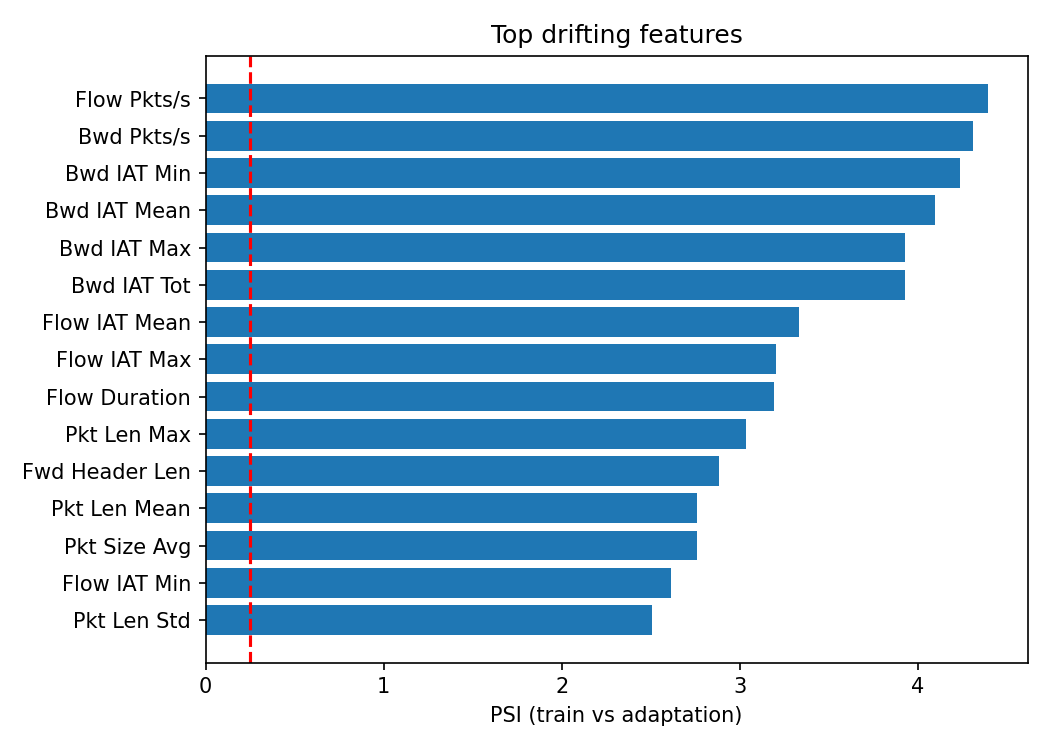

fig_final_ddos_recall.png


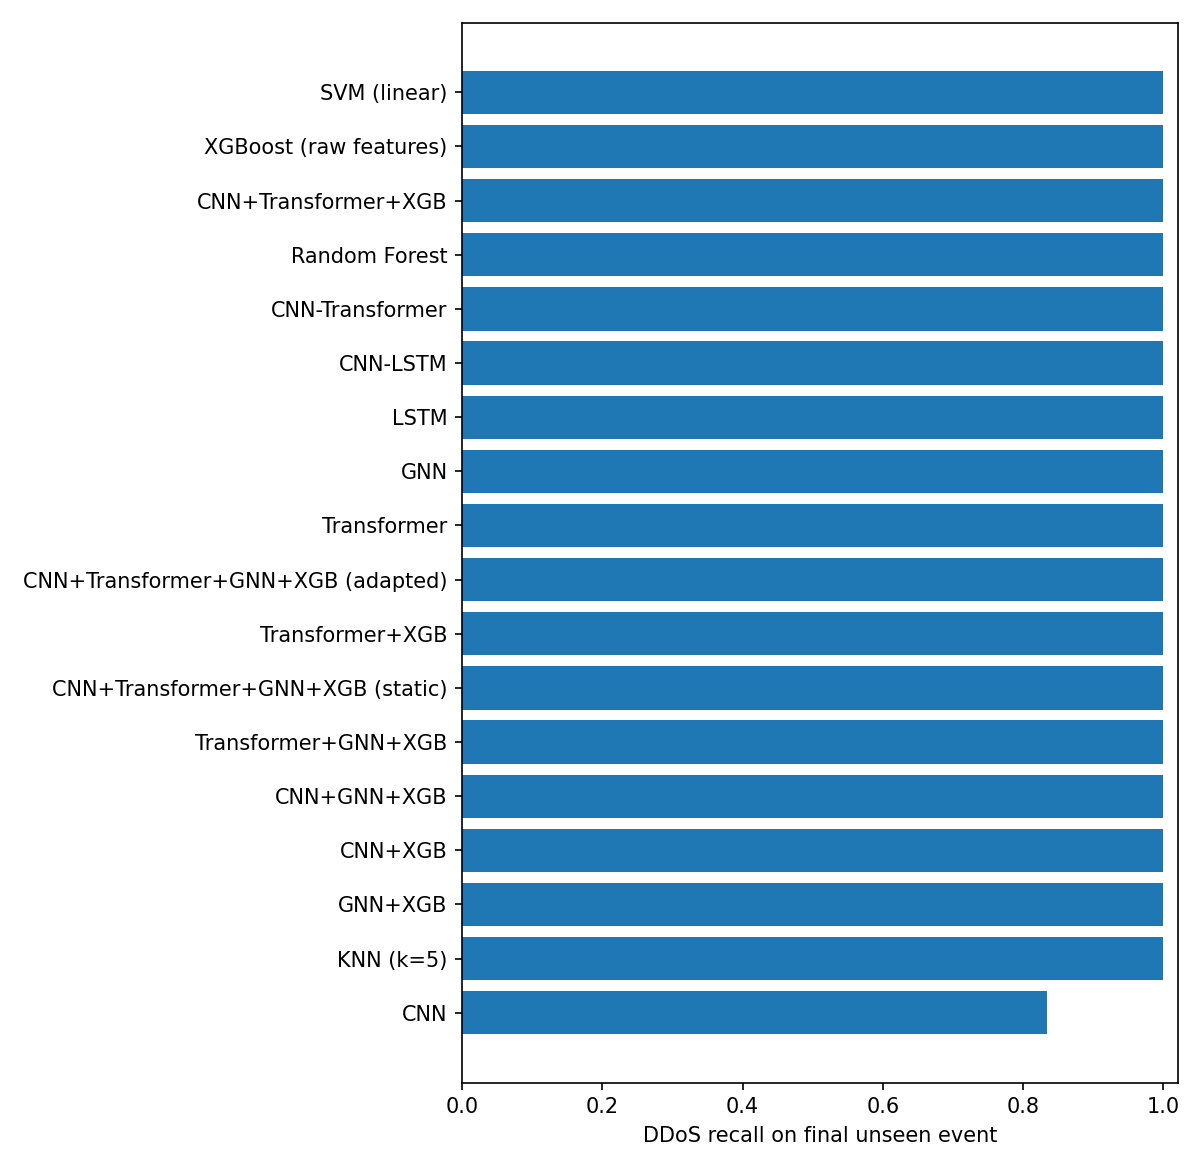

fig_latency_vs_recall.png


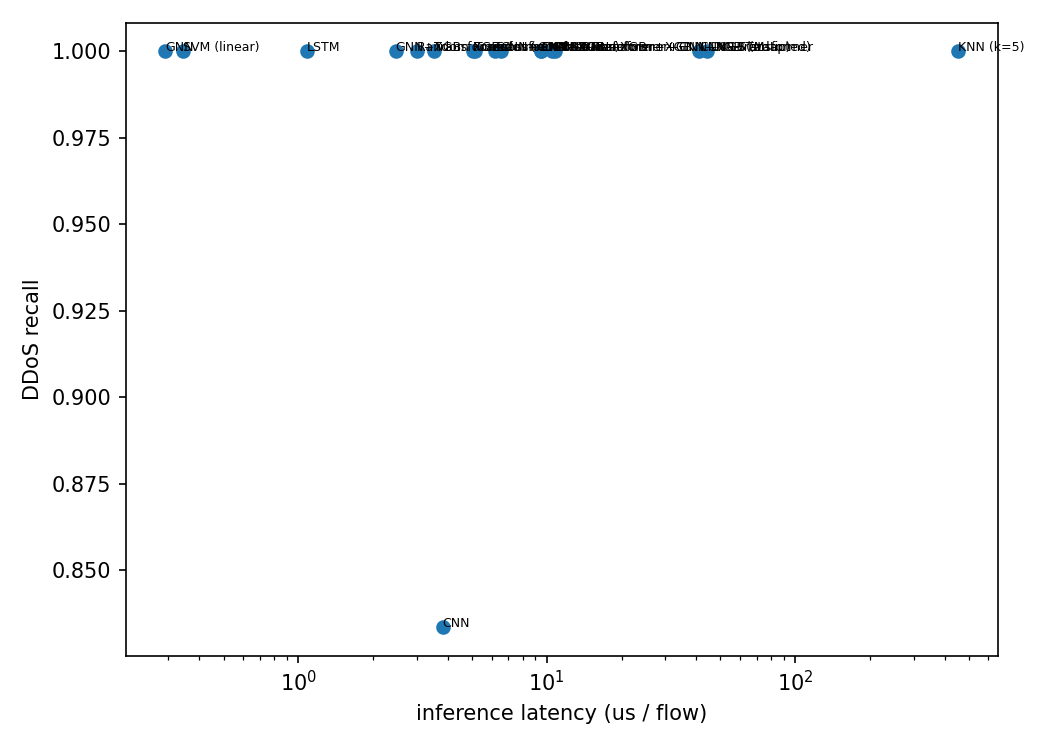

fig_training_curves.png


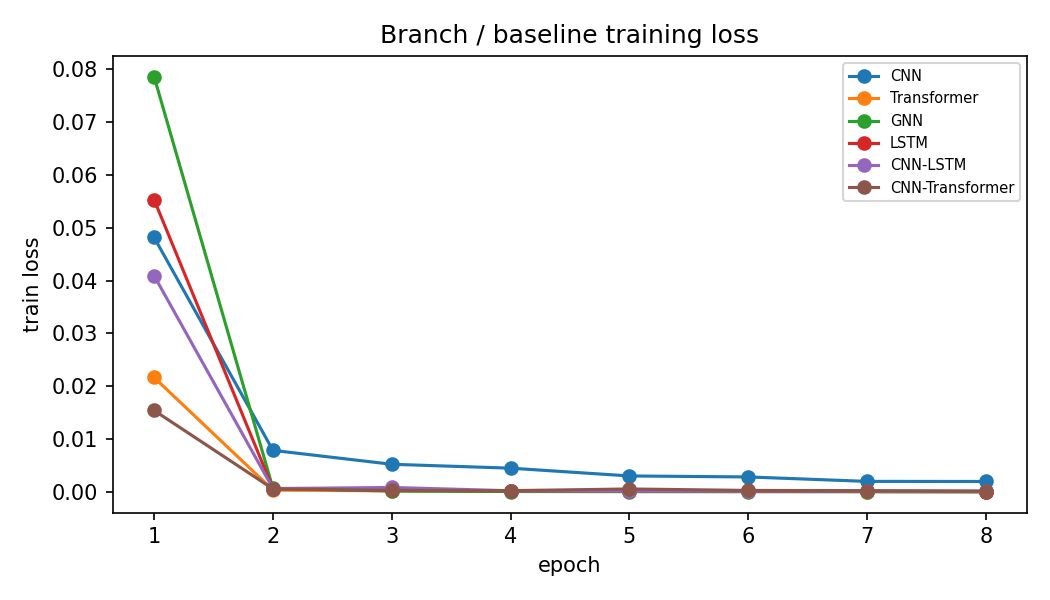

fig_validation_recall.png


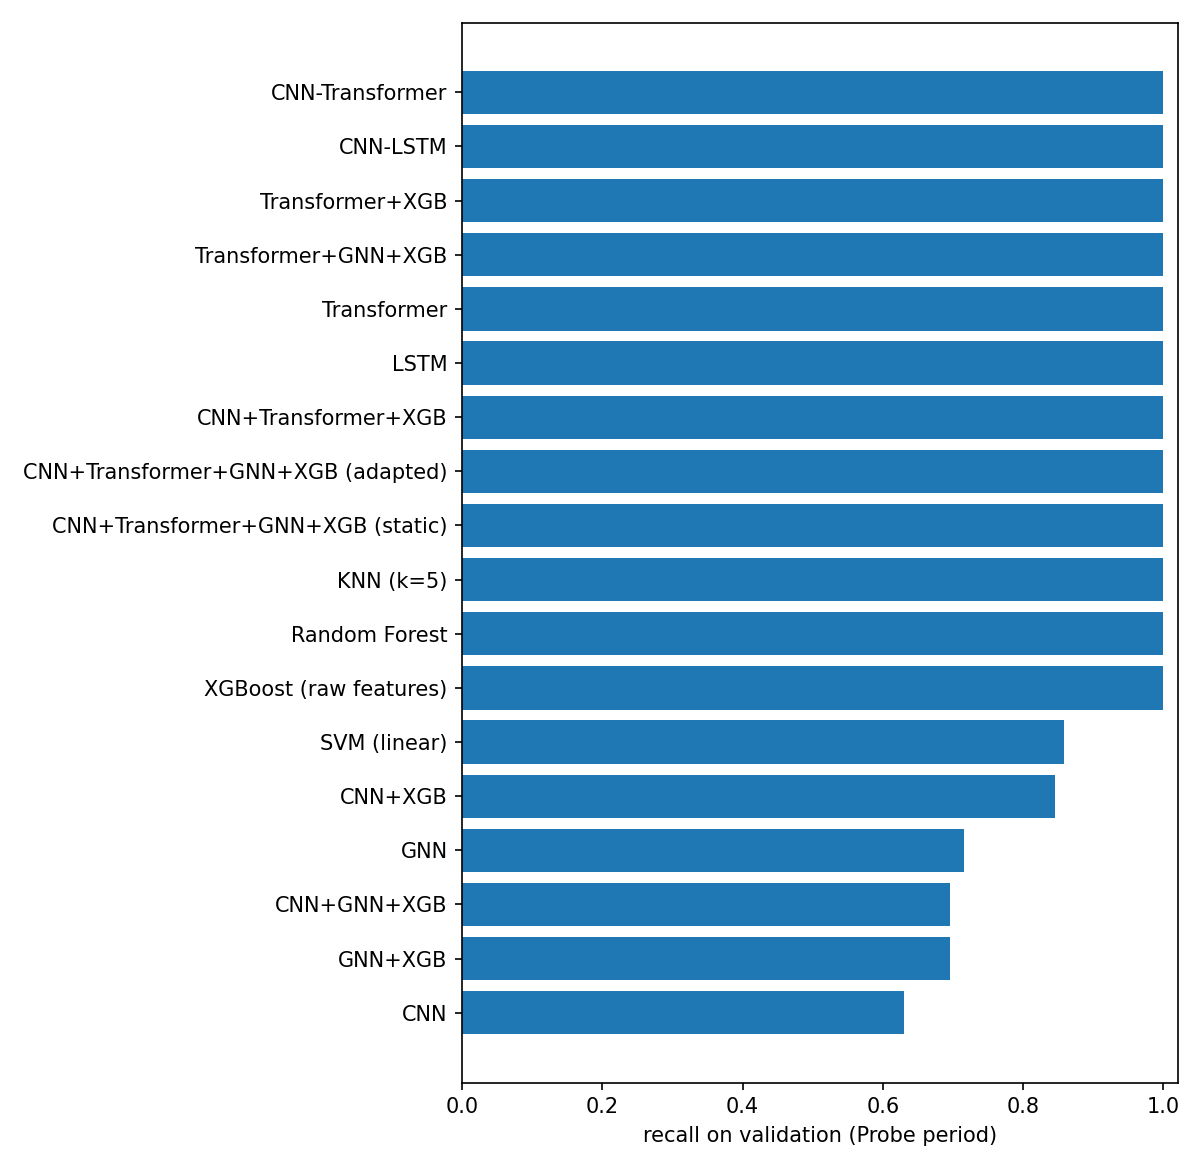

In [ ]:
import os
from IPython.display import display, Image

out_dir = "/content/capstone_outputs"

png_files = sorted([
    f for f in os.listdir(out_dir)
    if f.lower().endswith(".png")
])

print(f"Found {len(png_files)} images:\n")

for f in png_files:
    print("=" * 80)
    print(f)
    print("=" * 80)
    display(Image(filename=os.path.join(out_dir, f)))

In [ ]:
# Optional: list generated artifacts.
import os
for root, dirs, files_ in os.walk("capstone_outputs"):
    for f in sorted(files_):
        print(os.path.join(root, f))
